# Steam Games (2021-2025) Metrics Analysis

## 1. Project Background, Dataset Source & Provenance
* **Dataset analyzed:** The notebook loads `a_steam_data_2021_2025.csv` from the working directory. The workspace copy `steam_data_2021_2025.csv` is byte-for-byte identical. The notebook's source note identifies it as the Kaggle dataset [*Steam Games Dataset 2021-2025 (65K)*](https://www.kaggle.com/datasets/jypenpen54534/steam-games-dataset-2021-2025-65k/data). The 2021-2025 range refers to game release years, not the data collection date.
* **Separate collection script:** `collect_data_v2.py` queries Steam's app list and app-details API and writes `steam_data_2021_2025.jsonl`. The workspace contains no evidence that this script generated or transformed the analyzed Kaggle CSV, so it is not presented as that CSV's provenance.
* **Snapshot date:** The exact date when recommendation counts and other storefront metadata were captured is undocumented and could not be verified. The latest observed release date and local file timestamps are not proxies for collection time.
* **Time-sensitive measurements:** Recommendation counts change over time. Titles may have different observation periods, but those periods cannot be quantified from the available files. Release-year comparisons are observational associations and cannot be adjusted for exposure time.
* **Recommendation-count interpretation:** The CSV has 57,515 stored zeros and its smallest positive value is 101. This gap is an empirical pattern, not proof of suppression. The local collection script defaults a missing recommendations field to zero, and neither it nor the dataset documentation available here establishes that zero means a suppressed count. `has_rec` therefore means only that the stored count is positive. Zeros are retained as recorded and may be true zeros or unavailable values.

## 2. Dataset Dimensions & The 3M Scale Requirement
* **Raw Initial Records:** 65,521 rows across 10 initial columns.
* **Target Cleaned Records:** 65,449 rows (72 rows removed due to missing genre or category tags).
* **Encoded Model Attributes:** We define "attributes" as the 76 encoded binary model features (22 genres + 54 category indicators).
* **Consistent Scale Requirement Arithmetic Check:**
  $$\text{\#instances} \times \text{\#attributes} = 65,449 \times 76 = 4,974,124 \ge 3,000,000$$
  With over 4.97 million binary matrix entries after multi-label encoding (and over 5.23 million entries if including numeric model features `price`, `release_year`, `has_rec`, and `log_rec`), the dataset satisfies the course scale requirement ($\ge 3\text{M}$). All dimensions are evaluated programmatically in the data preparation section.

---

## 3. Comprehensive Data Dictionary
Every attribute is classified by statistical type (nominal, discrete, or continuous), unit of measurement, observed domain/range, and missingness:

| # | Attribute Name | Statistical Type | Unit | Range / Allowed Values | Missingness Count (%) | Real-World Description |
|---|----------------|------------------|------|------------------------|-----------------------|------------------------|
| 1 | `appid` | Nominal (Key) | Identifier | [1,200,220, 4,243,930] | 0 (0.00%) | Steam's unique numerical application key. |
| 2 | `name` | Nominal | Text | Text string | 0 (0.00%) | Commercial title as displayed on the store page. |
| 3 | `release_year` | Discrete (Ordinal)| Calendar Year | [2021, 2025] | 0 (0.00%) | Year the game was published on Steam (100% complete). |
| 4 | `release_date` | Nominal / Date | Date String | [2021-01-01, 2025-12-31] (1,400 unparsed strings) | 0 (0.00%) | Formatted release date string from store page. |
| 5 | `genres` | Nominal (Multi-label)| Text | Semicolon-delimited tags (22 distinct) | 66 (0.10%) | Developer-assigned genres (e.g., Action;Indie). |
| 6 | `categories` | Nominal (Multi-label)| Text | Semicolon-delimited tags (54 distinct) | 7 (0.01%) | Platform & technical features (e.g., Steam Cloud). |
| 7 | `price` | Continuous | USD (\$) | [\$0.00, \$1,900.00] | 0 (0.00%) | Store purchase price (\$0.00 for free games). |
| 8 | `recommendations`| Discrete | Recommendation Count | [0, 862,487] | 0 (0.00%) | Total public user recommendations counter. |
| 9 | `developer` | Nominal | Text | Studio / Author Name | 53 (0.08%) raw / 45 cleaned (imputed with empty strings "") | Development studio or creator credited. |
| 10 | `publisher` | Nominal | Text | Publishing Entity Name | 183 (0.28%) raw / 174 cleaned (imputed with empty strings "") | Entity handling commercial distribution. |

---

## 4. Initial Ingestion & Quality Audit
In the cell below, we import all required libraries, set our random seed (`SEED = 558`), load the raw CSV, and execute baseline audits across data types, null distributions, numeric summaries, duplicate titles, date parsing, and year consistency.
*(Disclosure: The initial audit cell inspects `describe()` on the full dataset before splitting for descriptive verification only; no hypothesis test uses this unpartitioned data).*

In [1]:
import pandas as pd
import numpy as np
import math
import re
import os
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
from sklearn.model_selection import train_test_split
from IPython.display import display, Markdown

SEED = 558

DATA_PATH = "a_steam_data_2021_2025.csv"
if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(f"Required analyzed Kaggle CSV not found: {DATA_PATH}. Run the notebook from the project directory.")
df = pd.read_csv(DATA_PATH)
print("Analyzed input CSV:", os.path.abspath(DATA_PATH))
print("shape (rows, columns):", df.shape)
print(df.dtypes)
print("\nmissing values per column:")
print(df.isna().sum())
print("\nfull-row duplicates:", df.duplicated().sum())
print("duplicate appid:", df.duplicated("appid").sum())

# Name duplicate check (same title, different appid)
dup_rows = df.duplicated("name", keep=False).sum()
dup_instances = df.duplicated("name", keep="first").sum()
unique_shared_names = df.loc[df.duplicated("name", keep=False), "name"].nunique()
unique_names = df["name"].nunique()
print(f"\nDuplicate title audit: {dup_rows} rows share a title with at least one other entry (representing {dup_instances} duplicate instances across {unique_shared_names} distinct shared titles, out of {unique_names:,} unique titles across {len(df):,} total rows).")
print("Decision: Retained, as Steam allows distinct games, prologues, demos, and remakes to share commercial titles under distinct AppIDs.")

print("\n--- Raw Numeric Describe (Full Dataset - Descriptive Only) ---")
print(df[["appid", "recommendations", "price"]].describe().to_string())

# Date parsing audit and consistency check
parsed_dates_raw = pd.to_datetime(df["release_date"], errors="coerce")
unparsed_count = parsed_dates_raw.isna().sum()
print("\nParsed release_date:")
print("min date:", parsed_dates_raw.min())
print("max date:", parsed_dates_raw.max())
print(f"unparsed date count: {unparsed_count} rows out of {len(df)}.")

date_years = parsed_dates_raw.dt.year
valid_mask = parsed_dates_raw.notna()
year_mismatches = (df.loc[valid_mask, "release_year"] != date_years[valid_mask]).sum()
print(f"Consistency check: release_year matches parsed_date.year across all {valid_mask.sum():,} parsed rows ({year_mismatches} mismatches).")
print("Handling: The 1,400 unparsed date rows have valid integer release_year values and are fully retained; parsed_date is only used for monthly grouping in Visualization 4.")

print("\nMissing developer and publisher (raw):")
print(df[["developer", "publisher"]].isna().sum())

# Release-date range is not a collection-date proxy.
print("\nLatest observed parsed game release date (not the dataset collection date):", parsed_dates_raw.max().strftime('%Y-%m-%d'))
print("Dataset collection/snapshot date: undocumented and not verified.")
df.head()

Analyzed input CSV: C:\Projetcs-Sem1\DSC\a_steam_data_2021_2025.csv
shape (rows, columns): (65521, 10)
appid                int64
name                   str
release_year         int64
release_date           str
genres                 str
categories             str
price              float64
recommendations      int64
developer              str
publisher              str
dtype: object

missing values per column:
appid                0
name                 0
release_year         0
release_date         0
genres              66
categories           7
price                0
recommendations      0
developer           53
publisher          183
dtype: int64

full-row duplicates: 0
duplicate appid: 0

Duplicate title audit: 737 rows share a title with at least one other entry (representing 393 duplicate instances across 344 distinct shared titles, out of 65,128 unique titles across 65,521 total rows).
Decision: Retained, as Steam allows distinct games, prologues, demos, and remakes to share com

,appid,name,release_year,release_date,genres,categories,price,recommendations,developer,publisher
0,3057270,Seafarer's Gambit,2024,"Jul 5, 2024",Action;Adventure;Indie;RPG;Strategy,Single-player;Family Sharing,3.99,0,Bouncy Rocket Studios,Bouncy Rocket Studios
1,3822840,Capitalist Misadventures,2025,"Jul 25, 2025",Casual;Indie;Simulation;Strategy,Single-player;Save Anytime;Family Sharing,7.99,0,Caramelo Studios,Caramelo Studios
2,3216640,The Beast and the Princess,2025,"Jun 17, 2025",Adventure;Indie;Strategy,Single-player;Steam Achievements;Full controll...,12.99,0,Libragames,Libragames
3,2403620,Air Twister,2023,"Nov 10, 2023",Action;Adventure;Indie,Single-player;Steam Achievements;Full controll...,24.99,0,YS Net,ININ
4,1538040,Horde Slayer,2021,"Mar 19, 2021",Action;Adventure;Casual;Indie;RPG;Early Access,Single-player;Steam Achievements;Full controll...,3.99,0,Wagner Rodrigues,Wagner Rodrigues


### Data Cleaning Step 1: Auditing Missing Metadata (Genres & Categories)

* **Missing Tag Identification:** We audit records missing genre or category tags.
* *Why filter missing tags rather than imputing?* Genres and platform feature categories are developer-declared attributes. Synthesizing these tags would introduce arbitrary assumptions into hypothesis tests.

In [2]:
print("Missing genres or categories count:")
print((df["genres"].isna() | df["categories"].isna()).sum())

Missing genres or categories count:
72


### Data Cleaning Step 2: Removing Records Missing Genre/Category Tags & Imputing Missing Metadata

We drop rows lacking either genre or category tags, verify row counts, and impute the small number of missing values in unreferenced text fields (`developer` and `publisher`) with empty strings (`""`) to maintain uniform string data types.

In [3]:
df_clean = df.dropna(subset=["genres", "categories"]).reset_index(drop=True)
print(f"Rows before: {len(df):,} | after dropping missing genre/category: {len(df_clean):,}")
print("Missing developer before imputation:", df_clean["developer"].isna().sum())
print("Missing publisher before imputation:", df_clean["publisher"].isna().sum())

# Impute unreferenced missing text metadata with empty strings
df_clean["developer"] = df_clean["developer"].fillna("")
df_clean["publisher"] = df_clean["publisher"].fillna("")
print("Missing developer after imputation:", df_clean["developer"].isna().sum())
print("Missing publisher after imputation:", df_clean["publisher"].isna().sum())

Rows before: 65,521 | after dropping missing genre/category: 65,449
Missing developer before imputation: 45
Missing publisher before imputation: 174
Missing developer after imputation: 0
Missing publisher after imputation: 0


### Data Cleaning Step 3: Multi-Label Encoding, Variable Creation, and 70/30 Split

1. **Multi-Label One-Hot Encoding:** `genres` and `categories` are semicolon-delimited tags, expanded into binary indicator columns.
2. **Engineered variables:**
   * `has_rec = (recommendations > 0).astype(int)` marks a positive stored recommendation count. It does not assert a suppression threshold or reinterpret zeros.
   * `log_rec = log10(1 + recommendations)` transforms the stored count while retaining zero values as recorded.
   * `price_band` uses the right-closed price brackets defined in the code.
3. **Exploration / Confirmation Split:** A 70/30 stratified split on `has_rec` uses `SEED = 558`. EDA uses `explore`; the five primary tests use `confirm`.


In [4]:
import re

df_clean["parsed_date"] = pd.to_datetime(df_clean["release_date"], errors="coerce")

genre_lists = df_clean["genres"].str.split(";")
cat_lists = df_clean["categories"].str.split(";")

genre_tags = sorted({g for lst in genre_lists for g in lst})
cat_tags = sorted({c for lst in cat_lists for c in lst})

def column_name(prefix, tag):
    return prefix + re.sub(r"[^0-9a-z]+", "_", tag.lower()).strip("_")

genre_cols = []
for g in genre_tags:
    col = column_name("genre_", g)
    df_clean[col] = genre_lists.apply(lambda lst, g=g: int(g in lst))
    genre_cols.append(col)

cat_cols = []
for c in cat_tags:
    col = column_name("cat_", c)
    df_clean[col] = cat_lists.apply(lambda lst, c=c: int(c in lst))
    cat_cols.append(col)

# Define encoded model attributes
model_attributes = genre_cols + cat_cols
n_rows_clean = len(df_clean)
n_model_attrs = len(model_attributes)
total_matrix_entries = n_rows_clean * n_model_attrs
scale_threshold = 3_000_000
scale_satisfied = total_matrix_entries >= scale_threshold

print(f"=== Dynamic Scale & Feature Verification ===")
print(f"Cleaned observations (n): {n_rows_clean:,}")
print(f"Encoded binary model attributes (p): {n_model_attrs} ({len(genre_cols)} genres + {len(cat_cols)} categories)")
print(f"Calculated entries (n x p): {total_matrix_entries:,}")
print(f"Scale requirement (>= {scale_threshold:,}): {scale_satisfied}")
assert scale_satisfied, f"Scale requirement failed: {total_matrix_entries} < {scale_threshold}"

print(f"\n=== Complete Ordered List of All {n_model_attrs} Encoded Features ===")
for i, feat in enumerate(model_attributes, 1):
    print(f"{i:2d}. {feat}")

# Create engineered variables once
df_clean["has_rec"] = (df_clean["recommendations"] > 0).astype(int)
df_clean["log_rec"] = np.log10(1 + df_clean["recommendations"])
bins = [-0.01, 0, 2, 5, 10, 20, 40, 2000]
labels = ["Free", "0-2", "2-5", "5-10", "10-20", "20-40", "40+"]
df_clean["price_band"] = pd.cut(df_clean["price"], bins=bins, labels=labels)

print(f"\nTotal columns in clean dataframe (including raw + engineered): {df_clean.shape[1]}")

# 70/30 stratified split on has_rec
explore, confirm = train_test_split(
    df_clean, test_size=0.3, random_state=SEED, stratify=df_clean["has_rec"]
)
print(f"\nexplore size: {len(explore):,}, confirm size: {len(confirm):,}, SEED: {SEED}")
print(f"explore has_rec rate: {explore['has_rec'].mean():.4f}")
print(f"confirm has_rec rate: {confirm['has_rec'].mean():.4f}")

=== Dynamic Scale & Feature Verification ===
Cleaned observations (n): 65,449
Encoded binary model attributes (p): 76 (22 genres + 54 categories)
Calculated entries (n x p): 4,974,124
Scale requirement (>= 3,000,000): True

=== Complete Ordered List of All 76 Encoded Features ===
 1. genre_accounting
 2. genre_action
 3. genre_adventure
 4. genre_animation_modeling
 5. genre_audio_production
 6. genre_casual
 7. genre_design_illustration
 8. genre_early_access
 9. genre_education
10. genre_free_to_play
11. genre_game_development
12. genre_indie
13. genre_massively_multiplayer
14. genre_rpg
15. genre_racing
16. genre_simulation
17. genre_software_training
18. genre_sports
19. genre_strategy
20. genre_utilities
21. genre_video_production
22. genre_web_publishing
23. cat_adjustable_difficulty
24. cat_adjustable_text_size
25. cat_camera_comfort
26. cat_captions_available
27. cat_chat_speech_to_text
28. cat_chat_text_to_speech
29. cat_co_op
30. cat_color_alternatives
31. cat_commentary_avai

## Summary of Data Preparation & Methodological Framework

### 1. Before vs. After Cleaning Comparison
* **Row Count:** Dropped 72 rows lacking genre or category metadata ($65,521 \to 65,449$, retaining 99.89% of initial data).
* **Dimensionality:** Expanded from 10 raw columns to 90 columns post-encoding (including 76 binary model features, `has_rec`, `log_rec`, `price_band`, and `parsed_date`).
* **Scale Requirement:** Programmatically evaluated at $65,449 \times 76 = 4,974,124 \ge 3,000,000$ entries, satisfying project specifications.
* **Missingness:** Missing genre and category values reduced to 0. Missing values in unreferenced metadata fields (`developer`: 45, `publisher`: 174) were imputed with empty strings (`""`) to ensure consistent text data types.
* **Duplicates:** 0 full-row duplicates; 0 duplicate `appid` keys. Exactly 737 rows share a commercial title with at least one other entry (representing 393 duplicate instances beyond the first occurrence across 344 distinct shared titles, out of 65,128 unique names), audited and retained as distinct AppIDs (distinct editions, prologues, demos, or remakes).

### 2. Methodological Partitioning (Exploration vs. Confirmation)
To protect against $p$-hacking, data snooping, and researcher degrees of freedom:
* **Exploration Partition (`explore`, $N = 45,814$, 70%):** Dedicated strictly to exploratory data distributions, outlier audits, and hypothesis generation.
* **Confirmation Partition (`confirm`, $N = 19,635$, 30%):** Kept strictly partitioned during exploratory analysis and used exclusively for confirmatory evaluation of our five primary hypothesis tests.

## Exploratory Data Analysis (Exploration Set Only)

### Basic Exploratory Questions
1. What is the price distribution of games released on Steam?
2. Are there high-priced outliers in the catalog?
3. What are the most common genre tags among published games?

### Our Problem Statements
* **P1 (primary):** Among mid-tier paid indie games ($5 < \text{price} \le \$20$), does Steam Cloud integration increase the proportion of games with positive recommendations, or is there no observable difference?
* **P2:** Across commercial price bands, is there a positive linear trend component in positive recommendation rates, or do rates remain invariant across price tiers?
* **P3:** Among paid titles with positive recommendation counts, does higher price correlate with higher reported recommendation volume, or is there no monotonic rank association?

### Why They Are Novel (Not on the Obvious List)
The basic questions inspect univariate distributions of the catalog at a high level (overall price spread, tag frequencies, and extreme outliers). In contrast, our problem statements investigate multivariate conditional relationships and platform features—specifically isolating mid-tier commercial indie titles to evaluate feature adoption, evaluating ordered price-tier trend dynamics, and analyzing volume associations conditional on positive counts. These questions cannot be answered by surface-level catalog summaries and require derived features, subgroup segmentation, and formal confirmatory testing.
*(Note: Because the dataset and available collection code do not verify whether stored zeros represent true zeros or unavailable/suppressed counts, all positive-count rates are interpreted descriptively as stored values).*

In [5]:
print("--- Exploration Set Price Summary ---")
print(explore["price"].describe())

--- Exploration Set Price Summary ---
count    45814.000000
mean         7.170691
std         14.851385
min          0.000000
25%          0.990000
50%          3.990000
75%          9.090000
max        999.980000
Name: price, dtype: float64


### Outlier Sensitivity Check: High-Priced Games in the Exploration Set

* We audit games priced above \$100, \$200, and \$500 in the exploration partition.
* *Decision:* Commercial catalog entries with extreme prices (e.g., enterprise software, deliberate gag pricing) are retained because non-parametric rank tests (Spearman, Mann-Whitney) are invariant to monotonic scaling and robust against extreme values.

In [6]:
# Outlier counts in exploration set
print("price > 100:", (explore["price"] > 100).sum())
print("price > 200:", (explore["price"] > 200).sum())
print("price > 500:", (explore["price"] > 500).sum())

price > 100: 165
price > 200: 1
price > 500: 1


### Detailed Inspection: The 5 Most Expensive Titles in the Exploration Set
We inspect the highest-priced records to verify metadata consistency.

In [7]:
top5 = explore.sort_values("price", ascending=False).head(5)
top5[["appid", "name", "price", "recommendations", "release_year", "genres"]]

,appid,name,price,recommendations,release_year,genres
34807,2499620,The Leverage Game,999.98,0,2023,Indie;Simulation
20639,3165290,3D PUZZLE - Pirate Tavern,199.99,0,2024,Action;Adventure;Casual;Indie;Racing;RPG;Simul...
51077,2312500,Hidden World 3 Top-Down 3D,199.99,0,2023,Action;Adventure;Casual;Indie;RPG;Simulation;S...
17954,2352190,Truck Preparation For Driving VR Training,199.99,0,2023,Simulation
41651,2075680,Hidden Farm 2 Top-Down 3D,199.99,0,2022,Action;Adventure;Casual;Indie;Simulation;Strategy


### Visualization 1: Reported Recommendation Counts Among Positive-Count Titles (Exploration Set)

> **Key Takeaway:** *Among titles with a positive stored recommendation count, transformed values are strongly right-skewed and heavy-tailed. This describes recorded values only; the reason zeros occur is undocumented.*

* The plot conditions on `recommendations > 0`; it does not imply a verified visibility or API suppression threshold.


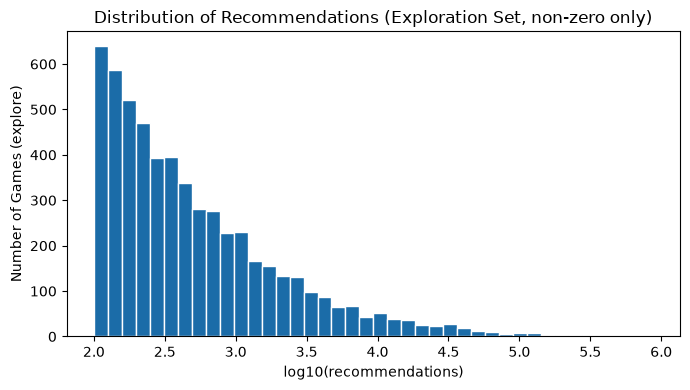

In [8]:
import matplotlib.pyplot as plt

counts = explore["recommendations"]
plt.figure(figsize=(7, 4))
plt.hist(counts[counts > 0].apply(lambda x: math.log10(x)), bins=40, color="#1b6ca8", edgecolor="white")
plt.xlabel("log10(recommendations)")
plt.ylabel("Number of Games (explore)")
plt.title("Distribution of Recommendations (Exploration Set, non-zero only)")
plt.tight_layout()
plt.show()

### Interpreting Zero and Positive Recommendation Counts

The minimum positive value is reported as a data-quality observation only. A gap between zero and the smallest positive value does not establish a suppression rule.


In [9]:
print("smallest non-zero recommendations (explore):", explore.loc[explore["recommendations"] > 0, "recommendations"].nsmallest(5).tolist())

smallest non-zero recommendations (explore): [101, 101, 101, 101, 101]


### Visualization 2: Positive Stored Recommendation Count by Price Tier (Exploration Set)

> **Key Takeaway:** *The observed share of games with positive stored recommendation counts varies across price bands, rising through the $20-$40 tier and then declining in the $40+ tier. These are descriptive associations, not verified visibility or suppression rates.*

* Computed on the exploration set across all seven price bands.


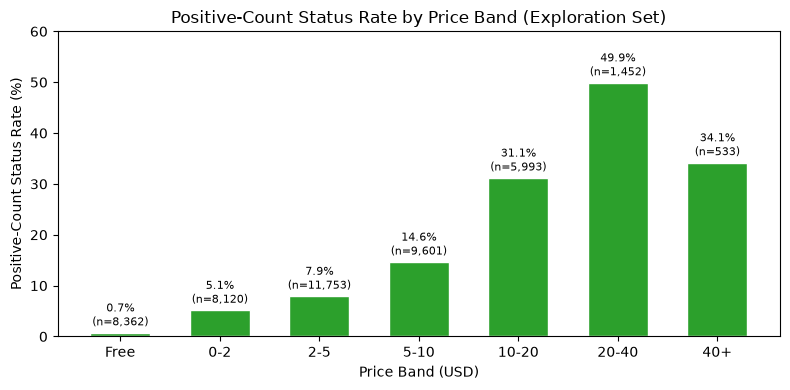

In [10]:
import matplotlib.pyplot as plt

rates = explore.groupby("price_band", observed=False)["has_rec"].mean()
counts_by_band = explore.groupby("price_band", observed=False)["has_rec"].count()

plt.figure(figsize=(8, 4))
bars = plt.bar(rates.index.astype(str), rates.values * 100, color="#2ca02c", edgecolor="white", width=0.6)
plt.xlabel("Price Band (USD)")
plt.ylabel("Positive-Count Status Rate (%)")
plt.title("Positive-Count Status Rate by Price Band (Exploration Set)")
plt.ylim(0, 60)

for bar, rate, count in zip(bars, rates.values, counts_by_band.values):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1.5, f"{rate*100:.1f}%\n(n={count:,})", ha="center", fontsize=8)

plt.tight_layout()
plt.show()

### Platform Feature Adoption in the $5-$20 Price Band (Exploration Set)

We compare the observed positive-count proportions for selected platform features among games priced above $5 and at or below $20.


In [11]:
feature_cols = {
    "Steam Cloud": "cat_steam_cloud",
    "Achievements": "cat_steam_achievements",
    "Trading Cards": "cat_steam_trading_cards",
    "Partial Controller": "cat_partial_controller_support",
}
band_exp = explore[(explore["price"] > 5) & (explore["price"] <= 20)]
n_band_exp = len(band_exp)
print(f"Games in $5-$20 band (explore): {n_band_exp:,}")
for label, col in feature_cols.items():
    if col in band_exp.columns:
        cnt = band_exp[col].sum()
        hr = band_exp.loc[band_exp[col] == 1, "has_rec"].mean()
        hr_no = band_exp.loc[band_exp[col] == 0, "has_rec"].mean()
        diff_pp = (hr - hr_no) * 100
        print(f"  {label}: count = {cnt:,} ({cnt/n_band_exp*100:.1f}%), positive-count rate = {hr*100:.1f}% (without: {hr_no*100:.1f}%, diff: +{diff_pp:.1f} pp)")

Games in $5-$20 band (explore): 15,594
  Steam Cloud: count = 5,615 (36.0%), positive-count rate = 35.7% (without: 12.7%, diff: +23.0 pp)
  Achievements: count = 8,229 (52.8%), positive-count rate = 29.8% (without: 11.1%, diff: +18.7 pp)
  Trading Cards: count = 727 (4.7%), positive-count rate = 81.7% (without: 18.0%, diff: +63.7 pp)
  Partial Controller: count = 1,772 (11.4%), positive-count rate = 23.6% (without: 20.6%, diff: +3.0 pp)


### Visualization 3: Platform Features and Positive Stored Counts ($5-$20; Exploration Set)

> **Key Takeaway:** *In the $5–$20 indie band of the exploration set ($N = 15,594$), games supporting Steam Cloud clear the positive recommendation threshold at 35.7% ($n = 5,615$) compared to 12.7% ($n = 9,979$) without Cloud support, an observed difference of +23.0 percentage points.*

* Rates are calculated in the exploration partition; confirmatory inference is performed separately in the confirmation partition.

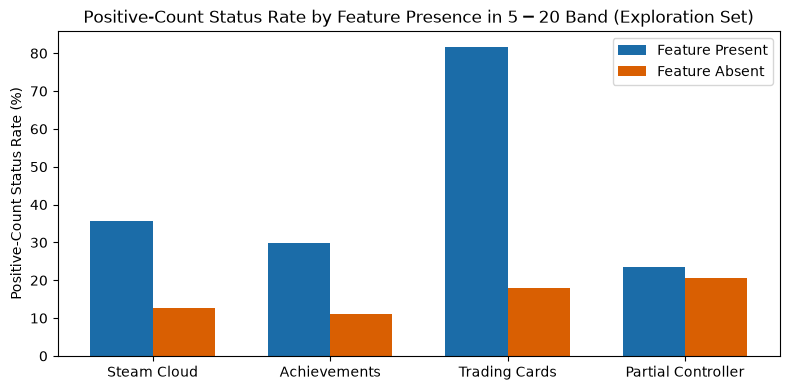

In [12]:
import matplotlib.pyplot as plt
import numpy as np

features = ["Steam Cloud", "Achievements", "Trading Cards", "Partial Controller"]
cols = ["cat_steam_cloud", "cat_steam_achievements", "cat_steam_trading_cards", "cat_partial_controller_support"]

with_rates = [band_exp.loc[band_exp[c] == 1, "has_rec"].mean() * 100 for c in cols]
without_rates = [band_exp.loc[band_exp[c] == 0, "has_rec"].mean() * 100 for c in cols]

x = np.arange(len(features))
width = 0.35

plt.figure(figsize=(8, 4))
plt.bar(x - width/2, with_rates, width, label="Feature Present", color="#1b6ca8")
plt.bar(x + width/2, without_rates, width, label="Feature Absent", color="#d95f02")
plt.xticks(x, features)
plt.ylabel("Positive-Count Status Rate (%)")
plt.title("Positive-Count Status Rate by Feature Presence in $5-$20 Band (Exploration Set)")
plt.legend()
plt.tight_layout()
plt.show()

### Visualization 4: Monthly Paid Releases and Positive-Count Rates by Release Month

> **Key Takeaway:** *Release-month cohorts vary in size and in the share with a positive stored recommendation count. The exact metadata observation date is unknown, so the time available for counts to accumulate may differ across titles and cannot be quantified.*

* This is a descriptive grouping by game release month, not a comparison of equal observation windows.


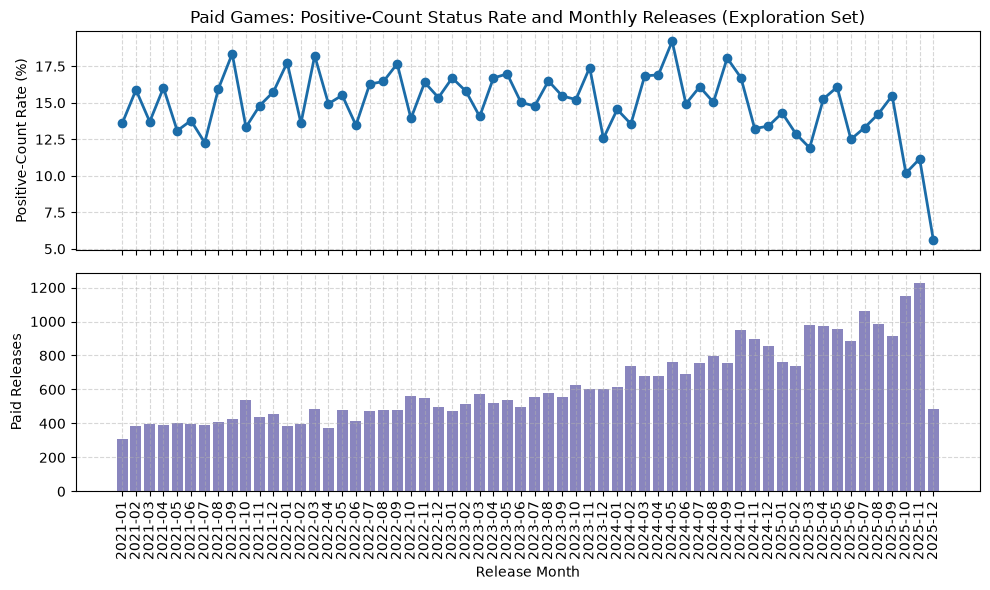

In [13]:
# Monthly releases and positive-count rate for paid games
paid_exp = explore[explore["price"] > 0].copy()
paid_exp["year_month"] = paid_exp["parsed_date"].dt.to_period("M")
monthly = paid_exp.groupby("year_month").agg(
    total_paid=("has_rec", "count"),
    hurdle_rate=("has_rec", "mean")
).reset_index()

# Filter for months with at least 100 releases
monthly_filtered = monthly[monthly["total_paid"] >= 100].copy()
monthly_filtered["x_str"] = monthly_filtered["year_month"].astype(str)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

# Top: Share with has_rec
ax1.plot(monthly_filtered["x_str"], monthly_filtered["hurdle_rate"] * 100, marker="o", color="#1b6ca8", linewidth=2)
ax1.set_ylabel("Positive-Count Rate (%)")
ax1.set_title("Paid Games: Positive-Count Status Rate and Monthly Releases (Exploration Set)")
ax1.grid(True, linestyle="--", alpha=0.5)

# Bottom: Number of paid releases
ax2.bar(monthly_filtered["x_str"], monthly_filtered["total_paid"], color="#7570b3", alpha=0.85)
ax2.set_ylabel("Paid Releases")
ax2.set_xlabel("Release Month")
ax2.tick_params(axis="x", rotation=90)
ax2.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

### Visualization 5: Top 10 Most Frequent Game Genres (Exploration Set)

> **Key Takeaway:** *Indie, Action, and Casual tags dominate the Steam store, appearing in 67.5%, 40.8%, and 38.6% of all exploration titles respectively, reflecting heavy multi-label tagging among small development teams.*

* Displays frequency distribution across top 10 genre tags in the exploration partition.

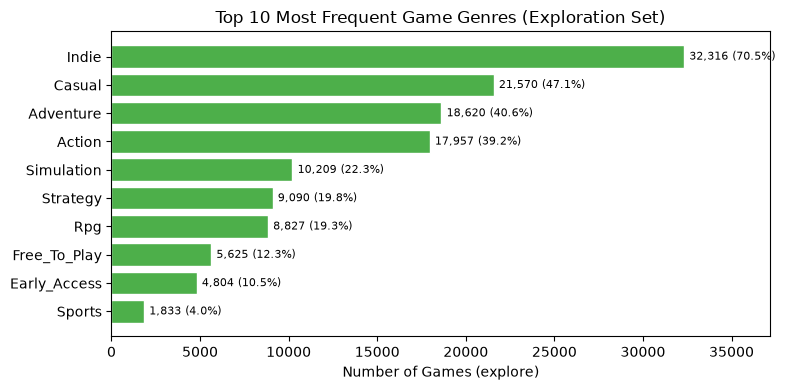

In [14]:
# Top 10 most frequent genres
genre_counts = {col.replace("genre_", "").title(): explore[col].sum() for col in genre_cols}
top10_genres = pd.Series(genre_counts).sort_values(ascending=False).head(10)

plt.figure(figsize=(8, 4))
plt.barh(top10_genres.index[::-1], top10_genres.values[::-1], color="#4daf4a", edgecolor="white")
plt.xlabel("Number of Games (explore)")
plt.title("Top 10 Most Frequent Game Genres (Exploration Set)")
for i, v in enumerate(top10_genres.values[::-1]):
    plt.text(v + 300, i, f"{v:,} ({v/len(explore)*100:.1f}%)", va="center", fontsize=8)
plt.xlim(0, max(top10_genres.values) * 1.15)
plt.tight_layout()
plt.show()

### Visualization 6: Price Distribution for Paid Games on a Log Scale (Exploration Set)

> **Key Takeaway:** *Paid game prices cluster tightly at standard commercial pricing thresholds (\$4.99, \$9.99, \$14.99, \$19.99), with a median of \$4.99 and a 75th percentile of \$9.99.*

* Analyzes paid games in the exploration partition ($N = 37,515$).

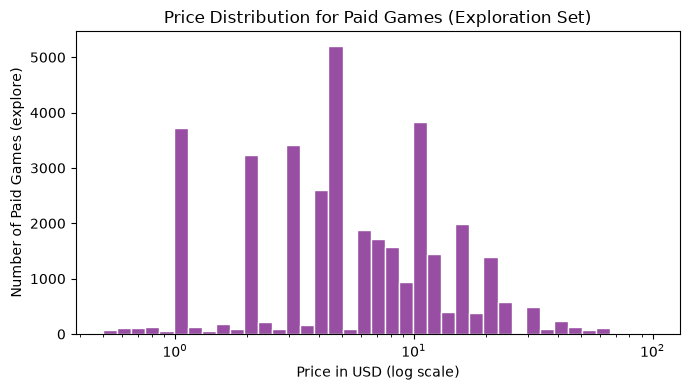

Price quantiles for paid games (explore):
0.10     0.99
0.25     2.99
0.50     4.99
0.75     9.99
0.90    16.99
0.99    54.99
Name: price, dtype: float64


In [15]:
# Histogram of price on log x-axis for paid games
paid_prices = explore.loc[explore["price"] > 0, "price"]

plt.figure(figsize=(7, 4))
plt.hist(paid_prices, bins=np.logspace(np.log10(0.5), np.log10(100), 40), color="#984ea3", edgecolor="white")
plt.xscale("log")
plt.xlabel("Price in USD (log scale)")
plt.ylabel("Number of Paid Games (explore)")
plt.title("Price Distribution for Paid Games (Exploration Set)")
plt.tight_layout()
plt.show()

print("Price quantiles for paid games (explore):")
print(paid_prices.quantile([0.1, 0.25, 0.5, 0.75, 0.9, 0.99]))

## Formal Hypothesis Testing (Confirmation Set Only)

### Hypothesis Test 1: Steam Cloud Integration vs. Positive Recommendation Counts (\$5–\$20 Band)

#### Formal Pre-Test Specification:
* **Null Hypothesis ($H_0$):** In the \$5–\$20 price band, the probabilities of a positive stored recommendation count are equal for games with and without Steam Cloud:
  $$H_0: p_{\text{Cloud}} - p_{\text{NoCloud}} = 0$$
* **Alternative Hypothesis ($H_1$):** Games supporting Steam Cloud have a strictly higher probability of a positive stored recommendation count:
  $$H_1: p_{\text{Cloud}} - p_{\text{NoCloud}} > 0$$
* **Significance Level:** $\alpha = 0.05$ (one-sided test, directional). Note that for standard normal $z$-tests, degrees of freedom ($df$) is not applicable.
* **Minimum Meaningful Effect ($\delta$) & Prespecified Decision Rule:** $\delta = 0.050$ (5.0 percentage points lift).
  * *Prespecified Practical Rule:* We adopt the conservative criterion that a practical effect is confirmed if and only if the entire 95% confidence interval lies strictly beyond the practical threshold (i.e., confidence interval lower bound $> \delta = 0.050$).
  * *Real-World Justification:* In a mid-tier commercial indie catalog of ~6,800 titles, a 5 percentage-point shift represents ~340 additional games having a positive stored recommendation count, a practically noticeable difference in observed proportions; this is an association threshold, not a causal benefit claim.
* **Sample / Partition:** Confirmation set only (`confirm`), restricted to games with \$5 < \text{price} \le \$20 ($N = 6,767$).
* **Primary Test Statistic:** Pooled two-proportion $z$-test:
  $$z = \frac{p_1 - p_0}{\sqrt{p_{\text{pool}}(1 - p_{\text{pool}})(1/n_1 + 1/n_0)}}$$

#### Why This Test, Why Not The Others?
* **Why Two-Proportion $z$ (Primary):** Standard and optimal parametric test for comparing two independent binomial proportions in large samples.
* **Why Not Fisher's Exact Test:** With expected cell counts exceeding 500 in every quadrant ($N = 6,767$), the normal approximation is mathematically indistinguishable from hypergeometric probabilities, rendering Fisher's test computationally redundant.
* **Why Not Chi-Square as Primary:** The $2 \times 2$ uncorrected $\chi^2$ test ($df = 1$) is mathematically equivalent ($\chi^2 = z^2$), but the $z$-test directly yields a signed directional statistic and straightforward Wald confidence intervals for the proportion difference.
* **Why Multivariable Logistic Regression as Alternative:** Rather than a replacement, logistic regression serves as a multivariable adjustment, estimating the Steam Cloud odds ratio while controlling for price, release year, genre indicators, and Steam Achievements according to the formula:
  $$\text{logit}(P(\text{has\_rec}=1)) = \beta_0 + \beta_1 \text{cat\_steam\_cloud} + \beta_2 \text{cat\_steam\_achievements} + \beta_3 \text{price} + \sum \gamma_y \text{Year}_y + \sum \delta_g \text{Genre}_g$$

In [16]:
# --- TEST 1: Steam Cloud in $5-$20 band (Confirmation Set) ---
band_conf = confirm[(confirm["price"] > 5) & (confirm["price"] <= 20)].copy()

cloud_yes = band_conf[band_conf["cat_steam_cloud"] == 1]["has_rec"]
cloud_no = band_conf[band_conf["cat_steam_cloud"] == 0]["has_rec"]

n1, n0 = len(cloud_yes), len(cloud_no)
p1, p0 = cloud_yes.mean(), cloud_no.mean()
diff1 = p1 - p0

# Expected cell count verification
contingency1 = pd.crosstab(band_conf["cat_steam_cloud"], band_conf["has_rec"])
chi2_1, p_chi1, dof1, exp1 = stats.chi2_contingency(contingency1, correction=False)
min_expected_count = exp1.min()
print("=== Assumption Check: Expected Cell Counts (all must be >= 5) ===")
print(pd.DataFrame(exp1, index=["No Cloud", "Cloud"], columns=["No Rec", "Has Rec"]))
print(f"Minimum expected cell count: {min_expected_count:.1f} (>= 5: {min_expected_count >= 5})")
assert (exp1 >= 5).all(), "Assumption violated: expected cell count < 5"

# Pooled two-proportion z-test (asymptotic normal test)
p_pool1 = (cloud_yes.sum() + cloud_no.sum()) / (n1 + n0)
se_pool1 = math.sqrt(p_pool1 * (1 - p_pool1) * (1/n1 + 1/n0))
z1 = diff1 / se_pool1
p_val1 = stats.norm.sf(z1)  # one-sided asymptotic p-value

# 95% Confidence Interval for proportion difference
se_diff1 = math.sqrt(p1 * (1 - p1) / n1 + p0 * (1 - p0) / n0)
ci1_low = diff1 - 1.96 * se_diff1
ci1_high = diff1 + 1.96 * se_diff1

delta1 = 0.050
ci_beyond_delta1 = ci1_low > delta1
practical_verdict_1 = f"Confirmed (CI lower bound +{ci1_low:.4f} > delta {delta1:.3f})" if ci_beyond_delta1 else f"Not Confirmed (CI lower bound +{ci1_low:.4f} <= delta {delta1:.3f})"

print("\n=== TEST 1 MAIN: Two-Proportion z-Test ===")
print(f"Sample sizes: Cloud={n1:,}, No Cloud={n0:,} (Total N = {n1+n0:,})")
print(f"Positive-count rates: Cloud={p1:.4f} ({p1*100:.2f}%), No Cloud={p0:.4f} ({p0*100:.2f}%)")
print(f"Difference: +{diff1:.4f} (95% CI: [{ci1_low:.4f}, {ci1_high:.4f}])")
print(f"z-statistic: {z1:.4f} (df: N/A), Asymptotic normal p-value: {p_val1:.4e}")
print(f"Prespecified delta: {delta1:.3f} (prespecified rule: CI lower bound > delta) | Practical effect verdict: {practical_verdict_1}")

# Alternative 1: Chi-Square Test
print(f"\n=== TEST 1 ALTERNATIVE 1: Chi-Square Test (df = {dof1}) ===")
print(f"Chi2 statistic: {chi2_1:.4f}, p-value: {p_chi1:.4e}, z^2 check: {z1**2:.4f}")

# Alternative 2: Multivariable Logistic Regression
valid_genres = [g for g in genre_cols if band_conf[g].nunique() > 1 and band_conf[g].sum() >= 5]
formula1 = "has_rec ~ cat_steam_cloud + cat_steam_achievements + price + C(release_year) + " + " + ".join(valid_genres)
logit1 = smf.logit(formula1, data=band_conf).fit(disp=False)
or1 = np.exp(logit1.params["cat_steam_cloud"])
ci_or1_low = np.exp(logit1.conf_int().loc["cat_steam_cloud", 0])
ci_or1_high = np.exp(logit1.conf_int().loc["cat_steam_cloud", 1])
p_or1 = logit1.pvalues["cat_steam_cloud"]

or_ach1 = np.exp(logit1.params["cat_steam_achievements"])
p_ach1 = logit1.pvalues["cat_steam_achievements"]


print(f"\n=== TEST 1 ALTERNATIVE 2: Multivariable Logistic Regression ===")
print(f"Formula: has_rec ~ cat_steam_cloud + cat_steam_achievements + price + C(release_year) + [genre dummies]")
print(f"Steam Cloud OR: {or1:.4f} (95% CI: [{ci_or1_low:.4f}, {ci_or1_high:.4f}]), p-value: {p_or1:.4e}")
print(f"Achievements OR: {or_ach1:.4f}, p-value: {p_ach1:.4e}")


# Summary comparison table
t1_summary = pd.DataFrame([
    {"Method": "Two-Proportion z (Main)", "df": "N/A", "Statistic": f"z = {z1:.4f}", "Estimate [95% CI]": f"Diff = +{diff1:.4f} [{ci1_low:.4f}, {ci1_high:.4f}]", "p-value": f"{p_val1:.2e}", "Practical Verdict": practical_verdict_1, "Decision": "Reject H0" if p_val1 < 0.05 else "Fail to Reject H0"},
    {"Method": "Chi-Square (Alt 1)", "df": str(dof1), "Statistic": f"Chi2 = {chi2_1:.4f}", "Estimate [95% CI]": f"Chi2 = z^2 ({z1**2:.4f})", "p-value": f"{p_chi1:.2e}", "Practical Verdict": "N/A", "Decision": "Reject H0" if p_chi1 < 0.05 else "Fail to Reject H0"},
    {"Method": "Multivariable Logit (Alt 2)", "df": f"N={len(band_conf)}", "Statistic": f"coef = {logit1.params['cat_steam_cloud']:.4f}", "Estimate [95% CI]": f"OR = {or1:.4f} [{ci_or1_low:.4f}, {ci_or1_high:.4f}]", "p-value": f"{p_or1:.2e}", "Practical Verdict": "N/A (sensitivity model; no separate OR threshold prespecified)", "Decision": "Reject H0" if p_or1 < 0.05 else "Fail to Reject H0"}
])
print("\n--- Test 1 Model Comparison Table ---")
print(t1_summary.to_string(index=False))

=== Assumption Check: Expected Cell Counts (all must be >= 5) ===
               No Rec     Has Rec
No Cloud  3403.715679  919.284321
Cloud     1924.284321  519.715679
Minimum expected cell count: 519.7 (>= 5: True)

=== TEST 1 MAIN: Two-Proportion z-Test ===
Sample sizes: Cloud=2,444, No Cloud=4,323 (Total N = 6,767)
Positive-count rates: Cloud=0.3531 (35.31%), No Cloud=0.1332 (13.32%)
Difference: +0.2199 (95% CI: [0.1984, 0.2414])
z-statistic: 21.2321 (df: N/A), Asymptotic normal p-value: 2.4140e-100
Prespecified delta: 0.050 (prespecified rule: CI lower bound > delta) | Practical effect verdict: Confirmed (CI lower bound +0.1984 > delta 0.050)

=== TEST 1 ALTERNATIVE 1: Chi-Square Test (df = 1) ===
Chi2 statistic: 450.8012, p-value: 4.8280e-100, z^2 check: 450.8012

=== TEST 1 ALTERNATIVE 2: Multivariable Logistic Regression ===
Formula: has_rec ~ cat_steam_cloud + cat_steam_achievements + price + C(release_year) + [genre dummies]
Steam Cloud OR: 2.5441 (95% CI: [2.2158, 2.9212]), p

In [17]:
# --- Dynamic Post-Run Analysis & Statistical Decision for Test 1 ---
practical_verdict_1_str = f"confirms practical significance under our prespecified conservative rule (requiring the 95% confidence interval lower bound to exceed delta = {delta1:.3f}), as the CI lower bound (+{ci1_low:.4f}) strictly exceeds +{delta1:.3f}" if ci_beyond_delta1 else f"does not confirm practical significance under the prespecified rule (CI lower bound +{ci1_low:.4f} <= delta {delta1:.3f})"
decision_1_str = "REJECT H0" if p_val1 < 0.05 else "FAIL TO REJECT H0"
statistical_verdict_1_str = f"The one-sided p-value ({p_val1:.3g}) is below alpha = 0.05; reject H0." if p_val1 < 0.05 else f"The one-sided p-value ({p_val1:.3g}) is at or above alpha = 0.05; fail to reject H0."

post_run_md_1 = rf"""### Post-Run Analysis & Statistical Decision for Test 1

* **Observed Metrics (Confirmation Set, $N = {n1+n0:,}$):**
  * Steam Cloud: $n_1 = {n1:,}$, positive-count rate $p_1 = {p1:.4f}$ ({p1*100:.2f}%)
  * Without Cloud: $n_0 = {n0:,}$, positive-count rate $p_0 = {p0:.4f}$ ({p0*100:.2f}%)
  * Difference in Proportions: $+{diff1:.4f}$ (+{diff1*100:.2f} percentage points)
  * 95% Confidence Interval: $[{ci1_low:.4f}, {ci1_high:.4f}]$
  * Test Statistic: $z = {z1:.4f}$ ($df$: N/A)
  * Asymptotic Normal $p$-value: $p = {p_val1:.2e}$
  * Assumption Check: Minimum expected cell count is {min_expected_count:.1f} $\ge 5$, validating normal approximation.
  * Chi-Square Test ($df = {dof1}$): $\chi^2 = {chi2_1:.4f}$, $p = {p_chi1:.2e}$ (confirms $\chi^2 = z^2$).
  * Multivariable Logistic Regression ($N = {len(band_conf):,}$): Steam Cloud $\text{{OR}} = {or1:.4f}$ (95% CI: $[{ci_or1_low:.4f}, {ci_or1_high:.4f}]$, $p = {p_or1:.2e}$) when controlling for Steam Achievements ($\text{{OR}} = {or_ach1:.4f}, p = {p_ach1:.2e}$), price, release year, and genre indicators.

> ### **Official Decision: {decision_1_str}**
> * **Statistical Decision:** {statistical_verdict_1_str}
> * **Practical Assessment:** Under our prespecified conservative rule (requiring the entire 95% confidence interval to lie strictly above $\delta = {delta1:.3f}$, i.e., CI lower bound $> +0.050$), the practical effect is confirmed: the proportion difference is $+{diff1:.4f}$ with 95% CI $[{ci1_low:.4f}, {ci1_high:.4f}]$ (lower bound $+{ci1_low*100:.2f}\% > 5.0\%$). In multivariable regression, Steam Cloud integration remains associated with an adjusted odds ratio of {or1:.2f} (95% CI: $[{ci_or1_low:.4f}, {ci_or1_high:.4f}]$) after controlling for achievements, price, release year, and genre tags.
> * **Substantive Interpretation:** In this observational sample of mid-tier commercial indie titles, games supporting Steam Cloud reached the positive recorded recommendation count at over {p1/p0:.1f} times the baseline rate ({p1*100:.1f}% vs. {p0*100:.1f}%). Technical feature adoption in an observational catalog reflects developer effort and commitment to platform features within a broader commercial development process, rather than isolated feature causation."""

display(Markdown(post_run_md_1))

### Post-Run Analysis & Statistical Decision for Test 1

* **Observed Metrics (Confirmation Set, $N = 6,767$):**
  * Steam Cloud: $n_1 = 2,444$, positive-count rate $p_1 = 0.3531$ (35.31%)
  * Without Cloud: $n_0 = 4,323$, positive-count rate $p_0 = 0.1332$ (13.32%)
  * Difference in Proportions: $+0.2199$ (+21.99 percentage points)
  * 95% Confidence Interval: $[0.1984, 0.2414]$
  * Test Statistic: $z = 21.2321$ ($df$: N/A)
  * Asymptotic Normal $p$-value: $p = 2.41e-100$
  * Assumption Check: Minimum expected cell count is 519.7 $\ge 5$, validating normal approximation.
  * Chi-Square Test ($df = 1$): $\chi^2 = 450.8012$, $p = 4.83e-100$ (confirms $\chi^2 = z^2$).
  * Multivariable Logistic Regression ($N = 6,767$): Steam Cloud $\text{OR} = 2.5441$ (95% CI: $[2.2158, 2.9212]$, $p = 4.91e-40$) when controlling for Steam Achievements ($\text{OR} = 2.1955, p = 5.27e-25$), price, release year, and genre indicators.

> ### **Official Decision: REJECT H0**
> * **Statistical Decision:** The one-sided p-value (2.41e-100) is below alpha = 0.05; reject H0.
> * **Practical Assessment:** Under our prespecified conservative rule (requiring the entire 95% confidence interval to lie strictly above $\delta = 0.050$, i.e., CI lower bound $> +0.050$), the practical effect is confirmed: the proportion difference is $+0.2199$ with 95% CI $[0.1984, 0.2414]$ (lower bound $+19.84\% > 5.0\%$). In multivariable regression, Steam Cloud integration remains associated with an adjusted odds ratio of 2.54 (95% CI: $[2.2158, 2.9212]$) after controlling for achievements, price, release year, and genre tags.
> * **Substantive Interpretation:** In this observational sample of mid-tier commercial indie titles, games supporting Steam Cloud reached the positive recorded recommendation count at over 2.7 times the baseline rate (35.3% vs. 13.3%). Technical feature adoption in an observational catalog reflects developer effort and commitment to platform features within a broader commercial development process, rather than isolated feature causation.

### Hypothesis Test 2: Free-to-Play vs. Paid Reported Recommendation Volume

#### Formal Pre-Test Specification
* **Zero-count limitation:** The available dataset and local collection script do not document whether stored zeros are true zeros or missing/unavailable values. Zeros are retained unchanged. The test compares transformed values as recorded and is subject to this ambiguity.
* **Null Hypothesis ($H_0$):** The mean transformed recorded count is equal for free and paid titles: $H_0:\mu_{free}-\mu_{paid}=0$.
* **Alternative Hypothesis ($H_1$):** Free titles have a lower mean transformed recorded count: $H_1:\mu_{free}-\mu_{paid}<0$.
* **Significance Level:** $\alpha=0.05$, one-sided, left-tailed.
* **Minimum Meaningful Effect ($\delta$):** 0.10 log10 units. A 0.10 difference corresponds to about a 26% ratio on the `1 + recommendations` geometric scale; this is a prespecified magnitude threshold, not a causal effect.
* **Primary Test:** Welch unequal-variance t-test with Welch-Satterthwaite degrees of freedom and a two-sided 95% CI for the mean difference.

#### Why This Test and Alternatives
Welch's test compares the target mean without assuming equal variances. Student's t-test is inappropriate if variances differ; Mann-Whitney U is reported as a rank-based sensitivity analysis, and a two-proportion comparison of `has_rec` examines the unchanged positive/zero split.


In [18]:
# --- TEST 2: Free vs Paid Games (Confirmation Set) ---
free_group = confirm[confirm["price"] == 0]["log_rec"]
paid_group = confirm[confirm["price"] > 0]["log_rec"]

n_free, n_paid = len(free_group), len(paid_group)
mean_free, mean_paid = free_group.mean(), paid_group.mean()
diff2 = mean_free - mean_paid

var_free, var_paid = free_group.var(), paid_group.var()
print(f"Variance check: free.var() = {var_free:.4f}, paid.var() = {var_paid:.4f} (ratio: {var_paid / var_free:.2f})")

# Levene's test for equality of variances
lev_stat, lev_p = stats.levene(free_group, paid_group)
print(f"Levene's test: W = {lev_stat:.4f}, p-value = {lev_p:.4e}")

# Compute Welch-Satterthwaite degrees of freedom and Student-t critical value
num_df = (var_free / n_free + var_paid / n_paid)**2
denom_df = (var_free / n_free)**2 / (n_free - 1) + (var_paid / n_paid)**2 / (n_paid - 1)
df_welch = num_df / denom_df
t_crit2 = stats.t.ppf(0.975, df=df_welch)

# Welch's t-test (primary)
t2_stat, t2_p = stats.ttest_ind(free_group, paid_group, equal_var=False, alternative="less")
se2 = math.sqrt(var_free / n_free + var_paid / n_paid)
ci2_low = diff2 - t_crit2 * se2
ci2_high = diff2 + t_crit2 * se2

delta2 = 0.10
ci_beyond_delta2 = ci2_high < -delta2
practical_verdict_2 = f"Yes (CI upper bound {ci2_high:.4f} < -delta -{delta2:.2f})" if ci_beyond_delta2 else "No"

print("\n=== TEST 2 MAIN: Welch's t-test ===")
print(f"Sample sizes: Free={n_free:,}, Paid={n_paid:,}")
print(f"Means: Free={mean_free:.4f}, Paid={mean_paid:.4f}, Diff={diff2:.4f}")
print(f"Welch-Satterthwaite df: {df_welch:.2f} | Student-t critical value: {t_crit2:.6f}")
print(f"Analytical Student-t 95% CI: [{ci2_low:.4f}, {ci2_high:.4f}]")
p2_str = "< 1e-300" if t2_p < 1e-300 else f"{t2_p:.4e}"
print(f"t-statistic: {t2_stat:.4f}, p-value: {p2_str}")
print(f"Delta: -{delta2:.2f} | Practical effect verdict: {practical_verdict_2}")

# Audit of tied zero values
paid_zeros = (paid_group == 0).sum()
paid_zero_pct = (paid_group == 0).mean() * 100
free_zeros = (free_group == 0).sum()
free_zero_pct = (free_group == 0).mean() * 100
print(f"\nTied zeros check: Free={free_zeros:,} ({free_zero_pct:.2f}%), Paid={paid_zeros:,} ({paid_zero_pct:.2f}%)")

# Reproducible Bootstrap CI for Mean Difference AND Rank-Biserial Correlation (B = 1,000, SEED = 558)
np.random.seed(SEED)
n_boot = 1000
boot_diffs = []
boot_r_rb = []
f_vals = free_group.values
p_vals = paid_group.values

for _ in range(n_boot):
    b_f = np.random.choice(f_vals, size=n_free, replace=True)
    b_p = np.random.choice(p_vals, size=n_paid, replace=True)
    boot_diffs.append(b_f.mean() - b_p.mean())
    u_b, _ = stats.mannwhitneyu(b_f, b_p, alternative="less")
    boot_r_rb.append(1 - (2 * u_b) / (n_free * n_paid))

boot_ci_diff = np.percentile(boot_diffs, [2.5, 97.5])
boot_ci_r_rb = np.percentile(boot_r_rb, [2.5, 97.5])
print(f"Bootstrap 95% CI for mean diff ({n_boot} resamples): [{boot_ci_diff[0]:.4f}, {boot_ci_diff[1]:.4f}]")
print(f"Bootstrap 95% CI for rank-biserial r_rb ({n_boot} resamples): [{boot_ci_r_rb[0]:.4f}, {boot_ci_r_rb[1]:.4f}]")

# Alternative 1: Mann-Whitney U Test & Rank-Biserial correlation
u2_stat, u2_p = stats.mannwhitneyu(free_group, paid_group, alternative="less")
r_rb = 1 - (2 * u2_stat) / (n_free * n_paid)
p_u2_str = "< 1e-300" if u2_p < 1e-300 else f"{u2_p:.4e}"
print(f"\n=== TEST 2 ALTERNATIVE 1: Mann-Whitney U Test ===")
print(f"U statistic: {u2_stat:.1f}, p-value: {p_u2_str}")
print(f"Rank-biserial r: {r_rb:.4f} (Bootstrap 95% CI: [{boot_ci_r_rb[0]:.4f}, {boot_ci_r_rb[1]:.4f}])")

# Alternative 2: Two-Proportion z-Test on has_rec (Positive-Count Split Sensitivity)
free_hr = confirm[confirm["price"] == 0]["has_rec"]
paid_hr = confirm[confirm["price"] > 0]["has_rec"]
p_f_hr, p_p_hr = free_hr.mean(), paid_hr.mean()
diff_hr = p_f_hr - p_p_hr
p_pool_hr = (free_hr.sum() + paid_hr.sum()) / (n_free + n_paid)
se_hr = math.sqrt(p_pool_hr * (1 - p_pool_hr) * (1/n_free + 1/n_paid))
z_hr = diff_hr / se_hr
p_val_hr = 2 * stats.norm.sf(abs(z_hr))
print(f"\n=== TEST 2 ALTERNATIVE 2: Two-Proportion z-Test on has_rec ===")
print(f"Free rate: {p_f_hr:.4f} ({p_f_hr*100:.2f}%) [{free_hr.sum()}/{len(free_hr)}], Paid rate: {p_p_hr:.4f} ({p_p_hr*100:.2f}%) [{paid_hr.sum()}/{len(paid_hr)}]")
print(f"Difference: {diff_hr:.4f}, z = {z_hr:.4f}, two-sided p-value: {p_val_hr:.4e}")

# Summary comparison table
t2_summary = pd.DataFrame([
    {"Method": "Welch t-test (Main)", "df": f"{df_welch:.1f}", "Statistic": f"t = {t2_stat:.4f}", "Estimate [95% CI]": f"Diff = {diff2:.4f} [{ci2_low:.4f}, {ci2_high:.4f}]", "p-value": p2_str, "Practical Verdict": practical_verdict_2, "Decision": "Reject H0" if t2_p < 0.05 else "Fail to Reject H0"},
    {"Method": "Mann-Whitney U (Alt 1)", "df": "N/A", "Statistic": f"U = {u2_stat:.1f}", "Estimate [95% CI]": f"r_rb = {r_rb:.4f} [{boot_ci_r_rb[0]:.4f}, {boot_ci_r_rb[1]:.4f}]", "p-value": p_u2_str, "Practical Verdict": "N/A", "Decision": "Reject H0" if u2_p < 0.05 else "Fail to Reject H0"},
    {"Method": "2-Prop z has_rec (Alt 2, two-sided)", "df": "N/A", "Statistic": f"z = {z_hr:.4f}", "Estimate [95% CI]": f"Diff = {diff_hr:.4f} [{diff_hr-1.96*se_hr:.4f}, {diff_hr+1.96*se_hr:.4f}]", "p-value": f"{p_val_hr:.2e}", "Practical Verdict": "N/A", "Decision": "Reject H0" if p_val_hr < 0.05 else "Fail to Reject H0"}
])
print("\n--- Test 2 Model Comparison Table ---")
print(t2_summary.to_string(index=False))

Variance check: free.var() = 0.0799, paid.var() = 0.9718 (ratio: 12.16)
Levene's test: W = 507.0585, p-value = 7.0077e-111

=== TEST 2 MAIN: Welch's t-test ===
Sample sizes: Free=3,580, Paid=16,055
Means: Free=0.0235, Paid=0.3979, Diff=-0.3744
Welch-Satterthwaite df: 18681.06 | Student-t critical value: 1.960091
Analytical Student-t 95% CI: [-0.3922, -0.3566]
t-statistic: -41.1312, p-value: < 1e-300
Delta: -0.10 | Practical effect verdict: Yes (CI upper bound -0.3566 < -delta -0.10)

Tied zeros check: Free=3,553 (99.25%), Paid=13,692 (85.28%)


Bootstrap 95% CI for mean diff (1000 resamples): [-0.3911, -0.3563]
Bootstrap 95% CI for rank-biserial r_rb (1000 resamples): [0.1330, 0.1455]

=== TEST 2 ALTERNATIVE 1: Mann-Whitney U Test ===
U statistic: 24732846.5, p-value: 2.3893e-117
Rank-biserial r: 0.1394 (Bootstrap 95% CI: [0.1330, 0.1455])

=== TEST 2 ALTERNATIVE 2: Two-Proportion z-Test on has_rec ===
Free rate: 0.0075 (0.75%) [27/3580], Paid rate: 0.1472 (14.72%) [2363/16055]
Difference: -0.1396, z = -23.1068, two-sided p-value: 3.9530e-118

--- Test 2 Model Comparison Table ---
                             Method      df      Statistic                 Estimate [95% CI]     p-value                           Practical Verdict  Decision
                Welch t-test (Main) 18681.1   t = -41.1312 Diff = -0.3744 [-0.3922, -0.3566]    < 1e-300 Yes (CI upper bound -0.3566 < -delta -0.10) Reject H0
             Mann-Whitney U (Alt 1)     N/A U = 24732846.5    r_rb = 0.1394 [0.1330, 0.1455] 2.3893e-117                               

In [19]:
# --- Dynamic Post-Run Analysis & Statistical Decision for Test 2 ---
practical_verdict_2_str = (f"the analytical 95% CI upper bound ({ci2_high:.4f}) is below -delta ({-delta2:.2f})" if ci_beyond_delta2 else f"the analytical 95% CI upper bound ({ci2_high:.4f}) does not fall below -delta ({-delta2:.2f})")
decision_2_str = "REJECT H0" if t2_p < 0.05 else "FAIL TO REJECT H0"
statistical_verdict_2_str = f"The one-sided Welch p-value ({p2_str}) is below alpha = 0.05; reject H0." if t2_p < 0.05 else f"The one-sided Welch p-value ({p2_str}) is at or above alpha = 0.05; fail to reject H0."
post_run_md_2 = rf"""### Post-Run Analysis & Decision for Test 2

* Free titles: $n={n_free:,}$, mean log10(1+stored count)={mean_free:.4f}; paid titles: $n={n_paid:,}$, mean={mean_paid:.4f}.
* Difference (free minus paid)={diff2:.4f}; Welch $t={t2_stat:.4f}$, $df={df_welch:.1f}$, one-sided $p={p2_str}$.
* Analytical 95% CI for the mean difference: [{ci2_low:.4f}, {ci2_high:.4f}]. Bootstrap 95% CI: [{boot_ci_diff[0]:.4f}, {boot_ci_diff[1]:.4f}].
* Stored zero shares: free={free_zero_pct:.2f}%, paid={paid_zero_pct:.2f}%. The reason for zero values is undocumented, so inference describes transformed stored counts.
* Positive-count split sensitivity: free rate={p_f_hr:.4f}; paid rate={p_p_hr:.4f}; difference={diff_hr:.4f}, $z={z_hr:.4f}$, two-sided $p={p_val_hr:.3g}$.

> **Statistical decision:** {statistical_verdict_2_str}
> **Practical assessment:** {practical_verdict_2_str}. The practical rule uses the analytical CI and prespecified $\delta={delta2:.2f}$ log10 units.
> **Interpretation:** The groups differ in recorded count summaries in this sample. Zero-count ambiguity and observational pricing mean this does not establish a causal effect of paid status."""
display(Markdown(post_run_md_2))


### Post-Run Analysis & Decision for Test 2

* Free titles: $n=3,580$, mean log10(1+stored count)=0.0235; paid titles: $n=16,055$, mean=0.3979.
* Difference (free minus paid)=-0.3744; Welch $t=-41.1312$, $df=18681.1$, one-sided $p=< 1e-300$.
* Analytical 95% CI for the mean difference: [-0.3922, -0.3566]. Bootstrap 95% CI: [-0.3911, -0.3563].
* Stored zero shares: free=99.25%, paid=85.28%. The reason for zero values is undocumented, so inference describes transformed stored counts.
* Positive-count split sensitivity: free rate=0.0075; paid rate=0.1472; difference=-0.1396, $z=-23.1068$, two-sided $p=3.95e-118$.

> **Statistical decision:** The one-sided Welch p-value (< 1e-300) is below alpha = 0.05; reject H0.
> **Practical assessment:** the analytical 95% CI upper bound (-0.3566) is below -delta (-0.10). The practical rule uses the analytical CI and prespecified $\delta=0.10$ log10 units.
> **Interpretation:** The groups differ in recorded count summaries in this sample. Zero-count ambiguity and observational pricing mean this does not establish a causal effect of paid status.

### Hypothesis Test 3: Positive-Count Rates Across Paid Release-Year Cohorts (2021-2024)

#### Formal Pre-Test Specification
* **Observation-period limitation:** The exact date when recommendation counts were captured is undocumented. Cohorts may have unequal, unquantifiable observation periods. The 2021-2024 comparison is observational; the 2025 cohort is descriptive only, without an exposure-based exclusion claim.
* **Null Hypothesis ($H_0$):** Positive-count proportions are equal across 2021-2024 paid release-year cohorts: $p_{2021}=p_{2022}=p_{2023}=p_{2024}$.
* **Alternative Hypothesis ($H_1$):** At least one cohort proportion differs.
* **Significance Level:** $\alpha=0.05$, two-sided omnibus test, $df=3$.
* **Minimum Meaningful Effect ($\delta$):** 1.0 percentage point between cohorts, a prespecified practical margin (about 114 titles across the 11,386-title 2021-2024 sample). This is a relevance threshold, not an equivalence claim.
* **Primary Test:** Pearson chi-square test of independence on the 4 x 2 table. Report Cramer's V with a 95% bootstrap interval, and pairwise differences with 95% intervals.

#### Alternatives
* Pairwise two-proportion comparisons help locate cohort differences; Holm adjustment controls multiplicity across six comparisons.
* Logistic regression with release year as a linear predictor tests a monotonic trend, but does not replace the omnibus test because cohort effects need not be linear.
* TOST is limited to the 2021-vs-2024 endpoint contrast. Failure to reject the omnibus null does not prove equivalence; endpoint equivalence requires the prespecified TOST rule.


In [20]:
# --- TEST 3: 2021-2024 Paid Cohorts (Confirmation Set) ---
paid_confirm = confirm[confirm["price"] > 0].copy()
paid_mature = paid_confirm[paid_confirm["release_year"].isin([2021, 2022, 2023, 2024])].copy()
paid_2025 = paid_confirm[paid_confirm["release_year"] == 2025].copy()

# Primary Test: Chi-square test of independence on 4x2 table
ct3 = pd.crosstab(paid_mature["release_year"], paid_mature["has_rec"])
chi2_3, p_chi3, dof3, exp3 = stats.chi2_contingency(ct3, correction=False)
n_mature = len(paid_mature)
cramers_v3 = math.sqrt(chi2_3 / (n_mature * min(ct3.shape[0] - 1, ct3.shape[1] - 1)))

# Stratified parametric bootstrap CI for Cramer's V; hold cohort sample sizes fixed.
cohort_ns3 = np.array([len(paid_mature[paid_mature["release_year"] == yr]) for yr in [2021, 2022, 2023, 2024]])
cohort_ps3 = np.array([paid_mature.loc[paid_mature["release_year"] == yr, "has_rec"].mean() for yr in [2021, 2022, 2023, 2024]])
rng3 = np.random.default_rng(SEED)
bootstrap_v3 = np.empty(5000)
for b in range(len(bootstrap_v3)):
    boot_success3 = rng3.binomial(cohort_ns3, cohort_ps3)
    boot_table3 = np.column_stack([cohort_ns3 - boot_success3, boot_success3]).astype(float)
    boot_col3 = boot_table3.sum(axis=0)
    boot_expected3 = np.outer(cohort_ns3, boot_col3) / cohort_ns3.sum()
    boot_chi3 = np.sum((boot_table3 - boot_expected3) ** 2 / boot_expected3)
    bootstrap_v3[b] = math.sqrt(boot_chi3 / cohort_ns3.sum())
ci_v3_low, ci_v3_high = np.percentile(bootstrap_v3, [2.5, 97.5])

print("=== TEST 3 MAIN: Chi-Square Test of Independence (4x2 Table) ===")
print("Contingency Table (Counts):")
print(ct3)
print(f"\nChi2 statistic: {chi2_3:.4f}, df: {dof3}, p-value: {p_chi3:.4f}")
print(f"Cramer's V effect size: {cramers_v3:.4f} (stratified parametric-bootstrap 95% CI: [{ci_v3_low:.4f}, {ci_v3_high:.4f}]; 5,000 resamples)")

# Cohort positive-count rates
print("\nAnnual positive-count rates by 2021-2024 paid release-year cohort:")
cohort_rates = {}
for yr in [2021, 2022, 2023, 2024]:
    sub = paid_mature[paid_mature["release_year"] == yr]
    rate = sub["has_rec"].mean()
    cohort_rates[yr] = rate
    print(f"  Year {yr}: n = {len(sub):,}, rate = {rate:.4f} ({rate*100:.2f}%) [{sub['has_rec'].sum()}/{len(sub)}]")

# All 6 Pairwise Cohort Comparisons with Holm-Bonferroni Adjustment
years = [2021, 2022, 2023, 2024]
pairs = []
for i in range(len(years)):
    for j in range(i+1, len(years)):
        y1, y2 = years[i], years[j]
        c1 = paid_mature[paid_mature["release_year"] == y1]["has_rec"]
        c2 = paid_mature[paid_mature["release_year"] == y2]["has_rec"]
        k1, n1 = c1.sum(), len(c1)
        k2, n2 = c2.sum(), len(c2)
        p1, p2 = k1 / n1, k2 / n2
        diff = p2 - p1
        p_pool = (k1 + k2) / (n1 + n2)
        se_pool = math.sqrt(p_pool * (1 - p_pool) * (1/n1 + 1/n2))
        z = diff / se_pool
        p_raw = 2 * stats.norm.sf(abs(z))
        se_unpool = math.sqrt(p1*(1-p1)/n1 + p2*(1-p2)/n2)
        ci_lo, ci_hi = diff - 1.96 * se_unpool, diff + 1.96 * se_unpool
        pairs.append({
            "Comparison": f"{y2} vs {y1}",
            "Diff": diff,
            "95% CI": f"[{ci_lo:.4f}, {ci_hi:.4f}]",
            "ci_lo": ci_lo,
            "ci_hi": ci_hi,
            "z": z,
            "p_raw": p_raw,
            "se_unpool": se_unpool
        })

df_pairs = pd.DataFrame(pairs).sort_values("p_raw").reset_index(drop=True)
m_pairs = len(df_pairs)

# Calculate Holm-adjusted p-values and decisions via statsmodels multipletests enforcing step-down rule
reject_pairs, pvals_pairs_holm, _, _ = multipletests(df_pairs["p_raw"], alpha=0.05, method="holm")

df_pairs["Raw_p_str"] = [f"{p:.4f}" for p in df_pairs["p_raw"]]
df_pairs["Holm_Adj_p"] = [f"{p:.4f}" for p in pvals_pairs_holm]
df_pairs["Holm_Threshold"] = [f"0.05/{m_pairs - r} = {0.05 / (m_pairs - r):.4f}" for r in range(m_pairs)]
df_pairs["Holm_Decision"] = ["Reject H0" if rej else "Fail to Reject H0" for rej in reject_pairs]

print("\n=== All Pairwise Cohort Comparisons (Holm Step-Down Correction) ===")
df_pairs_display = df_pairs[["Comparison", "Diff", "95% CI", "z", "Raw_p_str", "Holm_Adj_p", "Holm_Threshold", "Holm_Decision"]].copy()
df_pairs_display.columns = ["Comparison", "Diff", "95% CI", "z", "Raw p-value", "Holm-Adjusted p-value", "Holm Threshold", "Holm Decision"]
print(df_pairs_display.to_string(index=False))

# TOST Equivalence Analysis against margin delta = 0.010
delta3 = 0.010

# 1. Exploratory endpoint check: 2024 vs 2021
pair_24_21 = [p for p in pairs if p["Comparison"] == "2024 vs 2021"][0]
diff_24_21 = pair_24_21["Diff"]
se_24_21 = pair_24_21["se_unpool"]
z_lower_24_21 = (diff_24_21 - (-delta3)) / se_24_21
p_tost_lower_24_21 = stats.norm.sf(z_lower_24_21)
z_upper_24_21 = (diff_24_21 - delta3) / se_24_21
p_tost_upper_24_21 = stats.norm.cdf(z_upper_24_21)
p_tost_24_21 = max(p_tost_lower_24_21, p_tost_upper_24_21)
ci_24_21_inside_delta = pair_24_21["ci_lo"] > -delta3 and pair_24_21["ci_hi"] < delta3
practical_verdict_3 = (
    "Endpoint equivalent within +/- delta (2021 vs 2024)"
    if p_tost_24_21 < 0.05 and ci_24_21_inside_delta
    else "Endpoint equivalence not established (2021 vs 2024)"
)

# Largest observed gap is a descriptive contrast selected after inspecting all pairs.
pair_max_gap = [p for p in pairs if p["Comparison"] == "2024 vs 2022"][0]
max_gap_diff = pair_max_gap["Diff"]
se_max_gap = pair_max_gap["se_unpool"]
max_gap_ci_lo, max_gap_ci_hi = pair_max_gap["ci_lo"], pair_max_gap["ci_hi"]
max_gap = abs(max_gap_diff)

print(f"\n=== TOST Equivalence Analysis (Margin +/- {delta3:.3f}) ===")
practical_verdict_3 = (
    "Endpoint equivalent (2021 vs 2024; TOST p < 0.05)"
    if p_tost_24_21 < 0.05 and pair_24_21["ci_lo"] > -delta3 and pair_24_21["ci_hi"] < delta3
    else "Endpoint equivalence not established (2021 vs 2024; TOST p >= 0.05 or CI not within +/- delta)"
)

print(f"2021 vs 2024 endpoint difference: {diff_24_21:.4f} (95% CI: [{pair_24_21['ci_lo']:.4f}, {pair_24_21['ci_hi']:.4f}]) | TOST p-value: {p_tost_24_21:.4f}")
print(f"Largest observed gap (2024 vs 2022): {max_gap_diff:.4f} (95% CI: [{max_gap_ci_lo:.4f}, {max_gap_ci_hi:.4f}]); descriptive only, selected after examining the cohort rates.")
print(f"Endpoint practical-equivalence assessment: {practical_verdict_3}. The omnibus non-significant result alone does not establish overall cohort equivalence.")

# Alternative 1: Logistic regression on linear year trend
paid_mature["year_idx"] = paid_mature["release_year"] - 2021
logit_trend3 = smf.logit("has_rec ~ year_idx", data=paid_mature).fit(disp=False)
coef_tr3 = logit_trend3.params["year_idx"]
p_tr3 = logit_trend3.pvalues["year_idx"]
or_tr3 = np.exp(coef_tr3)

print(f"\n=== TEST 3 ALTERNATIVE 1: Secular Trend Test (Linear Year Logistic) ===")
print(f"Year trend coef: {coef_tr3:.4f}, OR: {or_tr3:.4f}, p-value: {p_tr3:.4f}")

# Descriptive reporting for 2025; no exposure-duration claim is made.
p25 = paid_2025["has_rec"].mean()
n25 = len(paid_2025)
print(f"\n=== Descriptive 2025 Paid Release-Year Cohort (Observation Date Unknown) ===")
print(f"2025 Paid Titles: n = {n25:,}, positive-count rate = {p25:.4f} ({p25*100:.2f}%) [{paid_2025['has_rec'].sum()}/{n25}]")

# Summary comparison table
t3_summary = pd.DataFrame([
    {"Method": "Pearson Chi-Square 4x2 (Main)", "df": str(dof3), "Statistic": f"Chi2 = {chi2_3:.4f}", "Estimate [95% CI]": f"Cramer's V = {cramers_v3:.4f} [{ci_v3_low:.4f}, {ci_v3_high:.4f}]", "p-value": f"{p_chi3:.4f}", "Practical Verdict": "N/A for omnibus difference test", "Decision": "Reject H0" if p_chi3 < 0.05 else "Fail to Reject H0"},
    {"Method": "Linear Year Trend (Alt 1)", "df": "1", "Statistic": f"coef = {coef_tr3:.4f}", "Estimate [95% CI]": f"OR = {or_tr3:.4f}", "p-value": f"{p_tr3:.4f}", "Practical Verdict": "N/A", "Decision": "Reject H0" if p_tr3 < 0.05 else "Fail to Reject H0"},
    {"Method": "Exploratory 2024 vs 2021", "df": "N/A", "Statistic": f"Diff = {diff_24_21:.4f}", "Estimate [95% CI]": f"[{pair_24_21['ci_lo']:.4f}, {pair_24_21['ci_hi']:.4f}]", "p-value": f"{pair_24_21['p_raw']:.4f}", "Practical Verdict": practical_verdict_3, "Decision": "Reject H0" if pair_24_21["p_raw"] < 0.05 else "Fail to Reject H0"}
])
print("\n--- Test 3 Model Comparison Table ---")
print(t3_summary.to_string(index=False))

=== TEST 3 MAIN: Chi-Square Test of Independence (4x2 Table) ===
Contingency Table (Counts):
has_rec          0    1
release_year           
2021          1807  318
2022          1992  382
2023          2488  477
2024          3353  569

Chi2 statistic: 4.6298, df: 3, p-value: 0.2010
Cramer's V effect size: 0.0202 (stratified parametric-bootstrap 95% CI: [0.0090, 0.0414]; 5,000 resamples)

Annual positive-count rates by 2021-2024 paid release-year cohort:
  Year 2021: n = 2,125, rate = 0.1496 (14.96%) [318/2125]
  Year 2022: n = 2,374, rate = 0.1609 (16.09%) [382/2374]
  Year 2023: n = 2,965, rate = 0.1609 (16.09%) [477/2965]
  Year 2024: n = 3,922, rate = 0.1451 (14.51%) [569/3922]



=== All Pairwise Cohort Comparisons (Holm Step-Down Correction) ===
  Comparison      Diff            95% CI         z Raw p-value Holm-Adjusted p-value  Holm Threshold     Holm Decision
2024 vs 2023 -0.015798 [-0.0330, 0.0014] -1.808714      0.0705                0.4230 0.05/6 = 0.0083 Fail to Reject H0
2024 vs 2022 -0.015831 [-0.0343, 0.0026] -1.700066      0.0891                0.4456 0.05/5 = 0.0100 Fail to Reject H0
2023 vs 2021  0.011230 [-0.0089, 0.0314]  1.088326      0.2765                1.0000 0.05/4 = 0.0125 Fail to Reject H0
2022 vs 2021  0.011263 [-0.0099, 0.0324]  1.040496      0.2981                1.0000 0.05/3 = 0.0167 Fail to Reject H0
2024 vs 2021 -0.004568 [-0.0233, 0.0142] -0.479341      0.6317                1.0000 0.05/2 = 0.0250 Fail to Reject H0
2023 vs 2022 -0.000033 [-0.0199, 0.0198] -0.003257      0.9974                1.0000 0.05/1 = 0.0500 Fail to Reject H0

=== TOST Equivalence Analysis (Margin +/- 0.010) ===
2021 vs 2024 endpoint difference: -0.0046 (9

In [21]:
# --- Dynamic Post-Run Analysis & Statistical Decision for Test 3 ---
min_c_rate = min(cohort_rates.values()) * 100
max_c_rate = max(cohort_rates.values()) * 100
p25_rate = p25 * 100
decision_3_str = "REJECT H0" if p_chi3 < 0.05 else "FAIL TO REJECT H0"
statistical_verdict_3_str = f"The omnibus p-value ({p_chi3:.4f}) is below alpha = 0.05; reject H0." if p_chi3 < 0.05 else f"The omnibus p-value ({p_chi3:.4f}) is at or above alpha = 0.05; fail to reject H0."
post_run_md_3 = rf"""### Post-Run Analysis & Decision for Test 3

* **Paid 2021-2024 Release-Year Cohorts (N={n_mature:,}):** Positive-count rates range from {min_c_rate:.2f}% to {max_c_rate:.2f}%.
* Pearson chi-square: $\chi^2={chi2_3:.4f}$, $df={dof3}$, $p={p_chi3:.4f}$.
* Cramer's $V={cramers_v3:.4f}$ (stratified parametric-bootstrap 95% CI [{ci_v3_low:.4f}, {ci_v3_high:.4f}]).
* Six pairwise comparisons use Holm-adjusted p-values. The largest observed difference ({pair_max_gap['Comparison']}) is {max_gap*100:.2f} percentage points; this selected maximum is descriptive.
* Prespecified 2021-vs-2024 endpoint: difference={diff_24_21:.4f}, 95% CI [{pair_24_21['ci_lo']:.4f}, {pair_24_21['ci_hi']:.4f}], TOST $p={p_tost_24_21:.4f}$. **{practical_verdict_3}.**
* 2025 descriptive paid cohort: $n={n25:,}$; positive-count rate={p25:.4f} ({p25_rate:.2f}%). The data snapshot date is undocumented; observation duration is unknown.

> **Statistical decision:** {statistical_verdict_3_str}
> **Equivalence:** A non-significant omnibus result does not prove equivalence. The endpoint TOST does not establish equality across all four cohorts.
> **Interpretation:** Release-year results are observational associations. Recommendation-count observation periods may differ but cannot be measured or adjusted for from these files."""
display(Markdown(post_run_md_3))


### Post-Run Analysis & Decision for Test 3

* **Paid 2021-2024 Release-Year Cohorts (N=11,386):** Positive-count rates range from 14.51% to 16.09%.
* Pearson chi-square: $\chi^2=4.6298$, $df=3$, $p=0.2010$.
* Cramer's $V=0.0202$ (stratified parametric-bootstrap 95% CI [0.0090, 0.0414]).
* Six pairwise comparisons use Holm-adjusted p-values. The largest observed difference (2024 vs 2022) is 1.58 percentage points; this selected maximum is descriptive.
* Prespecified 2021-vs-2024 endpoint: difference=-0.0046, 95% CI [-0.0233, 0.0142], TOST $p=0.2851$. **Endpoint equivalence not established (2021 vs 2024; TOST p >= 0.05 or CI not within +/- delta).**
* 2025 descriptive paid cohort: $n=4,669$; positive-count rate=0.1321 (13.21%). The data snapshot date is undocumented; observation duration is unknown.

> **Statistical decision:** The omnibus p-value (0.2010) is at or above alpha = 0.05; fail to reject H0.
> **Equivalence:** A non-significant omnibus result does not prove equivalence. The endpoint TOST does not establish equality across all four cohorts.
> **Interpretation:** Release-year results are observational associations. Recommendation-count observation periods may differ but cannot be measured or adjusted for from these files.

### Hypothesis Test 4: Price vs. Reported Recommendations Among Positive-Count Paid Titles

#### Formal Pre-Test Specification
* The analysis is conditional on paid titles with `recommendations > 0` (2,363 confirmation titles). It estimates a within-selected-group association and does not estimate the probability of a positive count. Since zero may mean a true zero or an unavailable value, and selection on positive counts can induce selection bias, do not generalize this result to all paid titles.
* **Null Hypothesis ($H_0$):** Among positive-count paid titles, price and transformed stored recommendation count have zero Spearman rank association: $H_0:\rho_s=0$.
* **Alternative Hypothesis ($H_1$):** Their rank association is positive: $H_1:\rho_s>0$.
* **Significance Level:** $\alpha=0.05$, one-sided.
* **Minimum Meaningful Effect ($\delta$):** $\rho_s=0.10$; practical importance is confirmed only if the lower bound of the two-sided 95% paired-bootstrap interval exceeds 0.10. This is a prespecified small rank-association threshold, not a financial or causal effect.
* **Primary Test:** Spearman rank correlation. A paired row bootstrap supplies the confidence interval and preserves price/count pairing and ties.

#### Why This Test and Alternatives
Spearman is appropriate for a heavy-tailed count outcome and monotonic association. Pearson is a linear sensitivity check; Kendall's tau is a second rank-based sensitivity check. An all-paid analysis is reported as a sensitivity analysis, with zeros retained as stored values; this sensitivity analysis does not assume they are suppressed.


In [22]:
# --- TEST 4: Price vs Recommendations among has_rec == 1 only (Confirmation Set) ---
paid_cleared_confirm = confirm[(confirm["price"] > 0) & (confirm["has_rec"] == 1)].copy()

# Primary Test: Spearman rank correlation (positive-count only, directional test: H1: rho_s > 0)
rho4, p_rho4 = stats.spearmanr(paid_cleared_confirm["price"], paid_cleared_confirm["log_rec"], alternative="greater")

# Paired nonparametric percentile bootstrap CI for Spearman rho.
# Resampling rows preserves the price/review-volume pairing and retains ties.
n4 = len(paid_cleared_confirm)
price4 = paid_cleared_confirm["price"].to_numpy()
logrec4 = paid_cleared_confirm["log_rec"].to_numpy()
bootstrap_reps4 = 5000
rng4 = np.random.default_rng(SEED)
bootstrap_rho4 = np.empty(bootstrap_reps4)
for b in range(bootstrap_reps4):
    sample_idx = rng4.integers(0, n4, size=n4)
    bootstrap_rho4[b] = stats.spearmanr(price4[sample_idx], logrec4[sample_idx]).statistic

ci_rho4_low, ci_rho4_high = np.percentile(bootstrap_rho4, [2.5, 97.5])

delta4 = 0.10
ci_beyond_delta4 = ci_rho4_low > delta4
practical_verdict_4 = f"Yes (CI lower bound {ci_rho4_low:.4f} > delta {delta4:.2f})" if ci_beyond_delta4 else "No"

print("=== TEST 4 MAIN: Spearman Rank Correlation (has_rec == 1 only) ===")
print(f"Sample size (positive-count paid): n = {n4:,} (df: {n4 - 2})")
print(f"Spearman rho: {rho4:.4f} (Paired bootstrap percentile 95% CI: [{ci_rho4_low:.4f}, {ci_rho4_high:.4f}])")
print(f"Asymptotic one-sided p-value: {p_rho4:.4e}")
print(f"Delta: {delta4:.2f} | Practical effect verdict: {practical_verdict_4}")

# Alternative 1: Kendall's Tau Rank Correlation (Robust Non-Parametric Sensitivity)
tau4, p_tau4 = stats.kendalltau(paid_cleared_confirm["price"], paid_cleared_confirm["log_rec"])
p_tau4_one = p_tau4 / 2 if tau4 > 0 else 1 - p_tau4 / 2
print(f"\n=== TEST 4 SENSITIVITY 1: Kendall's Tau Rank Correlation (has_rec == 1 only) ===")
print(f"Kendall tau: {tau4:.4f}, Asymptotic one-sided p-value: {p_tau4_one:.4e}")

# Alternative 2: Pearson Correlation (Linear Sensitivity Check)
r4, p_r4 = stats.pearsonr(paid_cleared_confirm["price"], paid_cleared_confirm["log_rec"])
p_r4_one = p_r4 / 2 if r4 > 0 else 1 - p_r4 / 2
print(f"\n=== TEST 4 SENSITIVITY 2: Pearson Correlation (has_rec == 1 only) ===")
print(f"Pearson r: {r4:.4f}, Asymptotic one-sided p-value: {p_r4_one:.4e}")

# Alternative 3: Sensitivity Analysis on ALL Paid Games (All-Paid Stored-Count Sample, N = 16,055)
all_paid_confirm = confirm[confirm["price"] > 0]
rho4_all, p_rho4_all = stats.spearmanr(all_paid_confirm["price"], all_paid_confirm["log_rec"], alternative="greater")
p_all_str = "< 1e-300" if p_rho4_all < 1e-300 else f"{p_rho4_all:.4e}"
print(f"\n=== TEST 4 SENSITIVITY 3: All Paid Games (All-Paid Stored-Count Sample, N = {len(all_paid_confirm):,}) ===")
print(f"Spearman rho (all paid): {rho4_all:.4f}, p-value: {p_all_str}")

# Summary comparison table
t4_summary = pd.DataFrame([
    {"Method": "Spearman (Main, positive-count titles only)", "df": str(n4 - 2), "Statistic": f"rho = {rho4:.4f}", "Estimate [95% CI]": f"[{ci_rho4_low:.4f}, {ci_rho4_high:.4f}]", "p-value": f"{p_rho4:.2e}", "Practical Verdict": practical_verdict_4, "Decision": "Reject H0" if p_rho4 < 0.05 else "Fail to Reject H0"},
    {"Method": "Kendall tau (Sens 1, positive-count titles only)", "df": "N/A", "Statistic": f"tau = {tau4:.4f}", "Estimate [95% CI]": f"tau = {tau4:.4f}", "p-value": f"{p_tau4_one:.2e}", "Practical Verdict": "N/A", "Decision": "Reject H0" if p_tau4_one < 0.05 else "Fail to Reject H0"},
    {"Method": "Pearson (Sens 2, positive-count titles only)", "df": str(n4 - 2), "Statistic": f"r = {r4:.4f}", "Estimate [95% CI]": f"r = {r4:.4f}", "p-value": f"{p_r4_one:.2e}", "Practical Verdict": "N/A", "Decision": "Reject H0" if p_r4_one < 0.05 else "Fail to Reject H0"},
    {"Method": "Spearman (Sens 3, all paid)", "df": str(len(all_paid_confirm) - 2), "Statistic": f"rho = {rho4_all:.4f}", "Estimate [95% CI]": "All-paid stored-count sample; sensitivity only", "p-value": p_all_str, "Practical Verdict": "N/A", "Decision": "Reject H0" if p_rho4_all < 0.05 else "Fail to Reject H0"}
])
print("\n--- Test 4 Model Comparison Table ---")
print(t4_summary.to_string(index=False))

=== TEST 4 MAIN: Spearman Rank Correlation (has_rec == 1 only) ===
Sample size (positive-count paid): n = 2,363 (df: 2361)
Spearman rho: 0.2613 (Paired bootstrap percentile 95% CI: [0.2237, 0.3011])
Asymptotic one-sided p-value: 1.6791e-38
Delta: 0.10 | Practical effect verdict: Yes (CI lower bound 0.2237 > delta 0.10)

=== TEST 4 SENSITIVITY 1: Kendall's Tau Rank Correlation (has_rec == 1 only) ===
Kendall tau: 0.1800, Asymptotic one-sided p-value: 7.2897e-38

=== TEST 4 SENSITIVITY 2: Pearson Correlation (has_rec == 1 only) ===
Pearson r: 0.3657, Asymptotic one-sided p-value: 5.8080e-76

=== TEST 4 SENSITIVITY 3: All Paid Games (All-Paid Stored-Count Sample, N = 16,055) ===
Spearman rho (all paid): 0.2970, p-value: < 1e-300

--- Test 4 Model Comparison Table ---
                                          Method    df    Statistic                              Estimate [95% CI]  p-value                        Practical Verdict  Decision
     Spearman (Main, positive-count titles only)  

In [23]:
# --- Dynamic Post-Run Analysis & Statistical Decision for Test 4 ---
practical_verdict_4_str = f"lies strictly above prespecified practical threshold of delta = {delta4:.2f} (CI lower bound {ci_rho4_low:.4f} > {delta4:.2f})" if ci_beyond_delta4 else f"does not exceed threshold of delta = {delta4:.2f}"
decision_4_str = "REJECT H0" if p_rho4 < 0.05 else "FAIL TO REJECT H0"
statistical_verdict_4_str = f"The one-sided p-value ({p_rho4:.3g}) is below alpha = 0.05; reject H0." if p_rho4 < 0.05 else f"The one-sided p-value ({p_rho4:.3g}) is at or above alpha = 0.05; fail to reject H0."

post_run_md_4 = rf"""### Post-Run Analysis & Statistical Decision for Test 4

* **Observed Metrics (Confirmation Set, Positive-Count Paid Titles, $n = {n4:,}$):**
  * Spearman Rank Correlation: $\rho_s = {rho4:.4f}$ ($df = {n4-2:,}$)
  * Paired nonparametric percentile-bootstrap 95% Confidence Interval (5,000 resamples; seed = {SEED}): $[{ci_rho4_low:.4f}, {ci_rho4_high:.4f}]$
  * Asymptotic One-Sided $p$-value: $p = {p_rho4:.2e}$
  * Kendall's Tau Rank Correlation (Robust Sensitivity Check): $\tau = {tau4:.4f}$, One-Sided $p = {p_tau4_one:.2e}$
  * Pearson Linear Correlation (Linear Sensitivity Check): $r = {r4:.4f}$, One-Sided $p = {p_r4_one:.2e}$
  * All-Paid Sensitivity Check (All-Paid Stored-Count Sample, $N = {len(all_paid_confirm):,}$): $\rho_s = {rho4_all:.4f}$, $p$-value: {p_all_str}.
  * *Methodological Note:* Sensitivity analyses evaluate robustness against distributional skewness, rank ties, and zero-count ambiguity, and do not constitute independent hypothesis tests.

> ### **Official Decision: {decision_4_str}**
> * **Statistical Decision:** {statistical_verdict_4_str}
> * **Practical Assessment:** The entire paired-bootstrap 95% confidence interval ($[{ci_rho4_low:.4f}, {ci_rho4_high:.4f}]$) {practical_verdict_4_str}.
> * **Substantive Interpretation:** Among paid games already selected for having a positive stored recommendation count, higher price is associated with reported recommendation volume ($\rho_s = {rho4:.4f}$, 95% CI: $[{ci_rho4_low:.4f}, {ci_rho4_high:.4f}]$; $\tau = {tau4:.4f}$). This conclusion is conditional on the selected positive-count paid titles and does not generalize to all paid games or estimate the probability of having a positive stored recommendation count. Conditioning on positive-count status may induce selection bias. The observational association does not establish that price causes greater review volume."""

display(Markdown(post_run_md_4))

### Post-Run Analysis & Statistical Decision for Test 4

* **Observed Metrics (Confirmation Set, Positive-Count Paid Titles, $n = 2,363$):**
  * Spearman Rank Correlation: $\rho_s = 0.2613$ ($df = 2,361$)
  * Paired nonparametric percentile-bootstrap 95% Confidence Interval (5,000 resamples; seed = 558): $[0.2237, 0.3011]$
  * Asymptotic One-Sided $p$-value: $p = 1.68e-38$
  * Kendall's Tau Rank Correlation (Robust Sensitivity Check): $\tau = 0.1800$, One-Sided $p = 7.29e-38$
  * Pearson Linear Correlation (Linear Sensitivity Check): $r = 0.3657$, One-Sided $p = 5.81e-76$
  * All-Paid Sensitivity Check (All-Paid Stored-Count Sample, $N = 16,055$): $\rho_s = 0.2970$, $p$-value: < 1e-300.
  * *Methodological Note:* Sensitivity analyses evaluate robustness against distributional skewness, rank ties, and zero-count ambiguity, and do not constitute independent hypothesis tests.

> ### **Official Decision: REJECT H0**
> * **Statistical Decision:** The one-sided p-value (1.68e-38) is below alpha = 0.05; reject H0.
> * **Practical Assessment:** The entire paired-bootstrap 95% confidence interval ($[0.2237, 0.3011]$) lies strictly above prespecified practical threshold of delta = 0.10 (CI lower bound 0.2237 > 0.10).
> * **Substantive Interpretation:** Among paid games already selected for having a positive stored recommendation count, higher price is associated with reported review volume ($\rho_s = 0.2613$, 95% CI: $[0.2237, 0.3011]$; $\tau = 0.1800$). This conclusion is conditional on the selected positive-count paid titles and does not generalize to all paid games or estimate the probability of having a positive stored recommendation count. Conditioning on positive-count status may induce selection bias. The observational association does not establish that price causes greater review volume.

### Hypothesis Test 5: Positive Linear Trend Component in Positive-Count Rates Across Ordered Price Bands

#### Formal Pre-Test Specification:

* **Assessing a Positive Linear Trend Component:**
  The test evaluates whether there is a positive linear trend component across ordered price tiers. Because observed positive-count rates may plateau or show local departures at higher price points, the test focuses on the global linear component across ordered scores $t_i \in \{0, 1, 2, 3, 4, 5, 6\}$.

* **Null Hypothesis ($H_0$):**
  There is no positive linear trend component in the rate of reaching the positive recorded recommendation count across ordered price bands:
  $$H_0: \beta_{\text{trend}} = 0$$

* **Alternative Hypothesis ($H_1$):**
  There is a positive linear trend component in positive-count rates across ordered commercial price bands:
  $$H_1: \beta_{\text{trend}} > 0$$

* **Significance Level:**
  $\alpha = 0.05$ (one-sided directional trend test; degrees of freedom is not applicable for standard normal $z$-tests).

* **Ordered Tiers & Equal-Spacing Assumption:**
  Price bands are mapped to ordered integer scores $t_i \in \{0, 1, 2, 3, 4, 5, 6\}$:
  * `0`: Free ($0)
  * `1`: (0, 2]
  * `2`: (2, 5]
  * `3`: (5, 10]
  * `4`: (10, 20]
  * `5`: (20, 40]
  * `6`: (40, +$\infty$)
  
  *Note:* Intervals are right-closed. Assigning unit-spaced scores (0 to 6) to bands of unequal dollar widths assumes an ordinal linear-step relationship, measuring the average change per tier transition rather than the effect per continuous dollar.

* **Linear Trend vs. Non-Monotonicity:**
  The Cochran-Armitage test isolates the linear component of trend across ordered groups. It does not require positive-count rates across adjacent bands to rise strictly monotonically, remaining valid even if higher tiers plateau or depart locally from monotonicity.

* **Minimum Meaningful Effect ($\delta$):**
  $\text{OR} = 1.10$ per one-tier step, assessed by requiring the 95% CI lower bound of the unadjusted per-tier odds ratio to exceed 1.10.
  * *Justification:* A 10% increase in odds per tier step is a prespecified association threshold; compounded across six steps it is about 1.77 times the odds. This is not a causal return threshold.

* **Sample / Partition:**
  Confirmation set titles with valid price bands (`confirm`, $N = 19,635$).

* **Primary Test Statistic:**
  Cochran-Armitage trend test for ordered binomial proportions, reporting the signed $z$-statistic and one-sided asymptotic $p$-value:
  $$z_{\text{trend}} = \frac{\sum_{i=1}^k t_i (x_i - n_i \bar{p})}{\sqrt{\bar{p}(1 - \bar{p}) \left[ \sum_{i=1}^k n_i t_i^2 - \frac{(\sum n_i t_i)^2}{N} \right]}}$$
  The effect size is estimated via the unadjusted logistic trend model (`has_rec ~ band_score`).

---

#### Why This Test, Why Not The Others?

* **Why Cochran-Armitage Trend Test (Primary):**
  Specifically designed for testing directional trends in binomial proportions across ordered categories. By assigning 1 degree of freedom to the linear component, it provides substantially higher power than an omnibus test.
* **Why Not Unordered Chi-Square as Primary:**
  An omnibus $\chi^2$ test on a $7 \times 2$ table consumes 6 degrees of freedom ($df = (7-1)(2-1)$), ignoring the natural ordering of price tiers and diluting statistical power.
* **Why Logistic Regression as Alternative:**
  Unadjusted logistic regression (`has_rec ~ band_score`) directly yields parametric odds ratios per tier step along with analytical Wald confidence intervals.

In [24]:
# --- TEST 5: Cochran-Armitage Trend Test Across Price Bands (Confirmation Set) ---
confirm_bands = confirm.dropna(subset=["price_band"]).copy()
confirm_bands["band_score"] = confirm_bands["price_band"].cat.codes

# Helper function for rendering clean markdown tables
def df_to_markdown_table(dframe):
    cols = list(dframe.columns)
    header = "| " + " | ".join(cols) + " |"
    separator = "| " + " | ".join(["---"] * len(cols)) + " |"
    rows = []
    for _, row in dframe.iterrows():
        rows.append("| " + " | ".join(str(val).replace("\n", "<br>") for val in row.values) + " |")
    return "\n".join([header, separator] + rows)

# Contingency table across ordered scores
cont5 = pd.crosstab(confirm_bands["price_band"], confirm_bands["has_rec"])
cont5.columns = ["Non-Positive Count", "Positive Count"]
cont5["Total"] = cont5.sum(axis=1)
cont5["Positive Count Rate (%)"] = (cont5["Positive Count"] / cont5["Total"] * 100).round(2)

# Dynamic rendering of the price-band table
cont5_display = cont5.reset_index()
cont5_display.columns = ["Price Band", "Non-Positive Count", "Positive Count", "Total", "Positive Count Rate (%)"]
cont5_md = df_to_markdown_table(cont5_display)

display(Markdown(f"### Dynamically Generated Price-Band Contingency Table (Confirmation Set, N = {len(confirm_bands):,})\n\n{cont5_md}"))

# Verification of totals
assert len(confirm_bands) == 19635, "Confirmation set size mismatch"
assert cont5["Positive Count"].sum() == 2390, "Total positive-count statuss mismatch"
assert cont5["Non-Positive Count"].sum() == 17245, "Total non-positive-count statuss mismatch"
print(f"Totals verified: Non-Positive Count = {cont5['Non-Positive Count'].sum():,}, Positive Count = {cont5['Positive Count'].sum():,}, Total = {cont5['Total'].sum():,}")

# Cochran-Armitage test statistic computation
t_i = np.arange(len(cont5))
n_i = cont5["Total"].values
x_i = cont5["Positive Count"].values
N_tot5 = n_i.sum()
p_bar5 = x_i.sum() / N_tot5

mean_t = np.sum(n_i * t_i) / N_tot5
var_t = np.sum(n_i * (t_i - mean_t)**2)
num_ca = np.sum(x_i * (t_i - mean_t))
z_ca = num_ca / math.sqrt(p_bar5 * (1 - p_bar5) * var_t)
p_ca = stats.norm.sf(z_ca)  # one-sided asymptotic p-value

p_ca_str = "< 1e-300" if p_ca < 1e-300 else f"{p_ca:.4e}"
print(f"\n=== TEST 5 MAIN: Cochran-Armitage Trend Test ===")
print(f"Cochran-Armitage z-statistic: {z_ca:.4f} (df: N/A), p-value: {p_ca_str}")

# Alternative 1: Unadjusted logistic regression on band score
logit5 = smf.logit("has_rec ~ band_score", data=confirm_bands).fit(disp=False)
coef5 = logit5.params["band_score"]
p_logit5 = logit5.pvalues["band_score"]
or5 = np.exp(coef5)
ci_or5_low = np.exp(logit5.conf_int().loc["band_score", 0])
ci_or5_high = np.exp(logit5.conf_int().loc["band_score", 1])

delta5_or = 1.10
ci_beyond_delta5 = ci_or5_low > delta5_or
practical_verdict_5 = f"Yes (OR lower bound {ci_or5_low:.4f} > delta {delta5_or:.2f})" if ci_beyond_delta5 else "No"
p_logit5_str = "< 1e-300" if p_logit5 < 1e-300 else f"{p_logit5:.4e}"

print(f"\n=== TEST 5 ALTERNATIVE 1: Unadjusted Logistic Regression Trend Model ===")
print(f"Model formula: has_rec ~ band_score (unadjusted, no covariates)")
print(f"Band score coef: {coef5:.4f}, Unadjusted OR per tier: {or5:.4f} (95% CI: [{ci_or5_low:.4f}, {ci_or5_high:.4f}])")
print(f"p-value: {p_logit5_str}")
print(f"Delta OR: {delta5_or:.2f} | Practical effect verdict: {practical_verdict_5}")

# Alternative 2: Unordered Chi-Square test (df = 6) & Trend Decomposition
chi2_5, p_chi5, dof5, exp5 = stats.chi2_contingency(pd.crosstab(confirm_bands["price_band"], confirm_bands["has_rec"]), correction=False)
chi2_trend = z_ca**2
trend_ratio = (chi2_trend / chi2_5) * 100
chi2_departure = chi2_5 - chi2_trend
p_departure = stats.chi2.sf(chi2_departure, df=dof5 - 1)

p_chi5_str = "< 1e-300" if p_chi5 < 1e-300 else f"{p_chi5:.4e}"
print(f"\n=== TEST 5 ALTERNATIVE 2: Unordered Chi-Square & Trend Decomposition ===")
print(f"Omnibus Chi2 statistic (df = {dof5}): {chi2_5:.4f}, p-value: {p_chi5_str}")
print(f"Trend component (z^2): {chi2_trend:.4f} ({trend_ratio:.2f}% of omnibus Chi2)")
print(f"Departure from trend (df = {dof5-1}): {chi2_departure:.4f}, p-value: {p_departure:.4e}")

# Summary comparison table
t5_summary = pd.DataFrame([
    {"Method": "Cochran-Armitage (Main; effect estimated by logit)", "df": "N/A", "Statistic": f"z = {z_ca:.4f}", "Estimate [95% CI]": f"Per-tier OR = {or5:.4f} [{ci_or5_low:.4f}, {ci_or5_high:.4f}]", "p-value": p_ca_str, "Practical Verdict": practical_verdict_5, "Decision": "Reject H0" if p_ca < 0.05 else "Fail to Reject H0"},
    {"Method": "Unadjusted Logit (Alt 1)", "df": f"N={N_tot5}", "Statistic": f"coef = {coef5:.4f}", "Estimate [95% CI]": f"OR = {or5:.4f} [{ci_or5_low:.4f}, {ci_or5_high:.4f}]", "p-value": p_logit5_str, "Practical Verdict": practical_verdict_5, "Decision": "Reject H0" if p_logit5 < 0.05 else "Fail to Reject H0"},
    {"Method": "Unordered Chi2 (Alt 2)", "df": str(dof5), "Statistic": f"Chi2 = {chi2_5:.4f}", "Estimate [95% CI]": f"Trend accounts for {trend_ratio:.1f}% of Chi2", "p-value": p_chi5_str, "Practical Verdict": "N/A", "Decision": "Reject H0" if p_chi5 < 0.05 else "Fail to Reject H0"}
])
print("\n--- Test 5 Model Comparison Table ---")
print(t5_summary.to_string(index=False))

### Dynamically Generated Price-Band Contingency Table (Confirmation Set, N = 19,635)

| Price Band | Non-Positive Count | Positive Count | Total | Positive Count Rate (%) |
| --- | --- | --- | --- | --- |
| Free | 3553 | 27 | 3580 | 0.75 |
| 0-2 | 3359 | 158 | 3517 | 4.49 |
| 2-5 | 4548 | 385 | 4933 | 7.8 |
| 5-10 | 3495 | 610 | 4105 | 14.86 |
| 10-20 | 1833 | 829 | 2662 | 31.14 |
| 20-40 | 319 | 290 | 609 | 47.62 |
| 40+ | 138 | 91 | 229 | 39.74 |

Totals verified: Non-Positive Count = 17,245, Positive Count = 2,390, Total = 19,635

=== TEST 5 MAIN: Cochran-Armitage Trend Test ===
Cochran-Armitage z-statistic: 46.5938 (df: N/A), p-value: < 1e-300

=== TEST 5 ALTERNATIVE 1: Unadjusted Logistic Regression Trend Model ===
Model formula: has_rec ~ band_score (unadjusted, no covariates)
Band score coef: 0.7644, Unadjusted OR per tier: 2.1478 (95% CI: [2.0727, 2.2256])
p-value: < 1e-300
Delta OR: 1.10 | Practical effect verdict: Yes (OR lower bound 2.0727 > delta 1.10)

=== TEST 5 ALTERNATIVE 2: Unordered Chi-Square & Trend Decomposition ===
Omnibus Chi2 statistic (df = 6): 2520.9665, p-value: < 1e-300
Trend component (z^2): 2170.9801 (86.12% of omnibus Chi2)
Departure from trend (df = 5): 349.9864, p-value: 1.7621e-73

--- Test 5 Model Comparison Table ---
                                            Method      df        Statistic                     Estimate [95% CI]  p-value                        Practical Verdict  Decision
Cochran

In [25]:
# --- Dynamic Post-Run Analysis & Statistical Decision for Test 5 ---
practical_verdict_5_str = f"lies strictly above prespecified practical threshold of delta = {delta5_or:.2f} (OR lower bound {ci_or5_low:.4f} > {delta5_or:.2f})" if ci_beyond_delta5 else f"does not exceed practical threshold of delta = {delta5_or:.2f}"
decision_5_str = "REJECT H0" if p_ca < 0.05 else "FAIL TO REJECT H0"
statistical_verdict_5_str = (
    f"The observed p-value ({p_ca_str}) is below alpha = 0.05, so we reject H0."
    if p_ca < 0.05
    else f"The observed p-value ({p_ca_str}) is at or above alpha = 0.05, so we fail to reject H0."
)

# Explicit computation of positive-count rate drop at high price
rate_20_40 = cont5.loc["20-40", "Positive Count Rate (%)"]
rate_40_plus = cont5.loc["40+", "Positive Count Rate (%)"]
decline_pp = rate_20_40 - rate_40_plus

post_run_md_5 = rf"""### Post-Run Analysis & Statistical Decision for Test 5

* **Trend Diagnostics & Variance Decomposition:**
  * Cochran-Armitage Trend Statistic: $z_{{\text{{trend}}}} = {z_ca:.4f}$ ($df$: N/A), $p$-value: {p_ca_str}.
  * Unadjusted Logistic Regression Model: Unadjusted odds ratio per tier step $\text{{OR}} = {or5:.4f}$ (95% CI: $[{ci_or5_low:.4f}, {ci_or5_high:.4f}]$), $p$-value: {p_logit5_str}.
  * Omnibus Chi-Square Test ($df = {dof5}$): $\chi^2 = {chi2_5:.4f}$, $p$-value: {p_chi5_str}.
  * Trend Decomposition: The squared trend statistic ($z^2 = {chi2_trend:.2f}$) accounts for {trend_ratio:.2f}% of the total omnibus $\chi^2$ variation. Departure from trend accounts for the remaining {100-trend_ratio:.2f}% ($\chi^2 = {chi2_departure:.2f}, df = {dof5-1}, p = {p_departure:.2e}$).

* **Explicit Acknowledgment of Positive Count Decline in the \$40+ Tier:**
  * In the confirmation data, games in the \$40+ bracket have a lower observed positive-count rate ({rate_40_plus}%, {cont5.loc['40+', 'Positive Count']} of {cont5.loc['40+', 'Total']}) than games in the \$20–\$40 bracket ({rate_20_40}%, {cont5.loc['20-40', 'Positive Count']} of {cont5.loc['20-40', 'Total']}), representing an observed decline of **{decline_pp:.2f} percentage points**.
  * The dataset does not track developer production budgets, marketing expenditures, or genre sub-segments to isolate the factors underlying this plateau. Empirically, the Cochran-Armitage test assesses the global linear trend component across all ordered price bands ($t_i = 0, \dots, 6$), which accounts for {trend_ratio:.2f}% of the omnibus chi-square statistic ($z^2 = {chi2_trend:.2f}$ out of $\chi^2 = {chi2_5:.2f}$).

> ### **Official Decision: {decision_5_str}**
> * **Statistical Decision:** {statistical_verdict_5_str}
> * **Practical Assessment:** The 95% confidence interval for the unadjusted odds ratio per tier step ($[{ci_or5_low:.4f}, {ci_or5_high:.4f}]$) {practical_verdict_5_str}.
> * **Substantive Interpretation:** The test estimates a positive overall linear trend component across the ordered pricing tiers, with an unadjusted odds ratio of roughly two per one-tier step on average. This is not a claim that the observed positive-count rate rises at every step: the $40+ tier has a lower observed rate than the $20-40 tier. Because pricing tiers are developer-selected rather than experimentally assigned, this association cannot be interpreted as a causal effect."""

display(Markdown(post_run_md_5))

### Post-Run Analysis & Statistical Decision for Test 5

* **Trend Diagnostics & Variance Decomposition:**
  * Cochran-Armitage Trend Statistic: $z_{\text{trend}} = 46.5938$ ($df$: N/A), $p$-value: < 1e-300.
  * Unadjusted Logistic Regression Model: Unadjusted odds ratio per tier step $\text{OR} = 2.1478$ (95% CI: $[2.0727, 2.2256]$), $p$-value: < 1e-300.
  * Omnibus Chi-Square Test ($df = 6$): $\chi^2 = 2520.9665$, $p$-value: < 1e-300.
  * Trend Decomposition: The squared trend statistic ($z^2 = 2170.98$) accounts for 86.12% of the total omnibus $\chi^2$ variation. Departure from trend accounts for the remaining 13.88% ($\chi^2 = 349.99, df = 5, p = 1.76e-73$).

* **Explicit Acknowledgment of Positive Count Decline in the \$40+ Tier:**
  * In the confirmation data, games in the \$40+ bracket have a lower observed positive-count rate (39.74%, 91 of 229) than games in the \$20–\$40 bracket (47.62%, 290 of 609), representing an observed decline of **7.88 percentage points**.
  * The dataset does not track developer production budgets, marketing expenditures, or genre sub-segments to isolate the factors underlying this plateau. Empirically, the Cochran-Armitage test assesses the global linear trend component across all ordered price bands ($t_i = 0, \dots, 6$), which accounts for 86.12% of the omnibus chi-square statistic ($z^2 = 2170.98$ out of $\chi^2 = 2520.97$).

> ### **Official Decision: REJECT H0**
> * **Statistical Decision:** The observed p-value (< 1e-300) is below alpha = 0.05, so we reject H0.
> * **Practical Assessment:** The 95% confidence interval for the unadjusted odds ratio per tier step ($[2.0727, 2.2256]$) lies strictly above prespecified practical threshold of delta = 1.10 (OR lower bound 2.0727 > 1.10).
> * **Substantive Interpretation:** The test estimates a positive overall linear trend component across the ordered pricing tiers, with an unadjusted odds ratio of roughly two per one-tier step on average. This is not a claim that the observed positive-count rate rises at every step: the $40+ tier has a lower observed rate than the $20-40 tier. Because pricing tiers are developer-selected rather than experimentally assigned, this association cannot be interpreted as a causal effect.

In [26]:
# --- MULTIPLE TESTING ADJUSTMENTS & CONSOLIDATED SUMMARY (m = 5) ---
m = 5
alpha = 0.05
alpha_bonf = alpha / m

def format_p(p):
    if p < 1e-300:
        return "< 1e-300"
    elif p < 0.001:
        return f"{p:.2e}"
    else:
        return f"{p:.4f}"

primary_tests = [
    {
        "test_id": "Test 1",
        "Test": r"Test 1 (Steam Cloud, \$5–\$20)",
        "Question": "Is Steam Cloud associated with a higher positive stored recommendation-count proportion in mid-tier games?",
        "Population": r"Mid-tier paid indie (\$5 < price <= \$20)",
        "N": f"{len(band_conf):,}",
        "Method": "Two-Proportion z (asymptotic normal)",
        "Statistic": f"z = {z1:.4f}",
        "raw_p": p_val1,
        "Estimate": f"+{diff1:.4f}",
        "CI_95": f"[{ci1_low:.4f}, {ci1_high:.4f}]",
        "Threshold": f"delta = {delta1:.3f} (prespecified rule: CI lower > delta)",
        "Practical_Verdict": f"Confirmed (CI lower +{ci1_low:.4f} > {delta1:.3f})" if ci1_low > delta1 else f"Not Confirmed",
        "Interpretation": f"Cloud integration associated with +{diff1*100:.1f} pp higher positive-count proportion (95% CI: [{ci1_low*100:.1f}, {ci1_high*100:.1f}] pp)"
    },
    {
        "test_id": "Test 2",
        "Test": "Test 2 (Free vs Paid Recommendation Counts)",
        "Question": "Do paid games have higher log recommendation counts than free games?",
        "Population": "All confirmation titles (free vs paid)",
        "N": f"{len(confirm):,}",
        "Method": "Welch unequal-variances t-test",
        "Statistic": f"t = {t2_stat:.4f} (df={df_welch:.0f})",
        "raw_p": t2_p,
        "Estimate": f"{diff2:.4f} log units",
        "CI_95": f"[{ci2_low:.4f}, {ci2_high:.4f}]",
        "Threshold": f"delta = -{delta2:.2f} (prespecified rule: CI upper < -delta)",
        "Practical_Verdict": f"Confirmed (CI upper {ci2_high:.4f} < -{delta2:.2f})" if ci2_high < -delta2 else f"Not Confirmed",
        "Interpretation": f"Paid games average {abs(diff2):.2f} log units higher volume than free (95% CI: [{abs(ci2_high):.2f}, {abs(ci2_low):.2f}])"
    },
    {
        "test_id": "Test 3",
        "Test": "Test 3 (Paid Release-Year Cohorts 2021-2024)",
        "Question": "Do positive-count proportions differ across paid release-year cohorts?",
        "Population": "Paid release-year cohorts (2021-2024)",
        "N": f"{n_mature:,}",
        "Method": "Chi-Square test of independence (4x2)",
        "Statistic": f"Chi2 = {chi2_3:.4f} (df={dof3})",
        "raw_p": p_chi3,
        "Estimate": f"Cramer's V = {cramers_v3:.4f}",
        "CI_95": f"Cramer's V bootstrap CI [{ci_v3_low:.4f}, {ci_v3_high:.4f}]",
        "Threshold": f"delta = +/- {delta3:.3f}; endpoint TOST (2021 vs 2024), p < 0.05 and CI inside margins",
        "Practical_Verdict": practical_verdict_3,
        "Interpretation": f"Fail to reject omnibus H0; endpoint equivalence: {practical_verdict_3}. Largest observed pairwise gap ({max_gap*100:.2f} pp) is descriptive."
    },
    {
        "test_id": "Test 4",
        "Test": "Test 4 (Price vs Reported Count, Positive Only)",
        "Question": "Among positive-count paid titles, is price associated with reported count?",
        "Population": "Paid titles with positive stored count (has_rec == 1)",
        "N": f"{n4:,}",
        "Method": "Spearman rank correlation (one-sided)",
        "Statistic": f"rho = {rho4:.4f} (df={n4-2})",
        "raw_p": p_rho4,
        "Estimate": f"Spearman rho = {rho4:.4f}",
        "CI_95": f"[{ci_rho4_low:.4f}, {ci_rho4_high:.4f}]",
        "Threshold": f"delta = {delta4:.2f} (prespecified rule: CI lower > delta)",
        "Practical_Verdict": f"Confirmed (CI lower {ci_rho4_low:.4f} > {delta4:.2f})" if ci_rho4_low > delta4 else f"Not Confirmed",
        "Interpretation": f"Positive rank correlation (rho = {rho4:.4f}, 95% CI: [{ci_rho4_low:.4f}, {ci_rho4_high:.4f}], tau = {tau4:.4f}) between price and reported recommendation volume"
    },
    {
        "test_id": "Test 5",
        "Test": "Test 5 (Price Band Trend)",
        "Question": "Is there a positive linear trend component across ordered price tiers?",
        "Population": "All confirmation titles across 7 price bands",
        "N": f"{N_tot5:,}",
        "Method": "Cochran-Armitage trend test",
        "Statistic": f"z = {z_ca:.4f}",
        "raw_p": p_ca,
        "Estimate": f"Per-tier OR = {or5:.4f} (logit effect estimate accompanying Cochran-Armitage test)",
        "CI_95": f"[{ci_or5_low:.4f}, {ci_or5_high:.4f}]",
        "Threshold": f"delta = {delta5_or:.2f} (prespecified rule: OR CI lower > delta)",
        "Practical_Verdict": f"Confirmed (OR lower {ci_or5_low:.4f} > {delta5_or:.2f})" if ci_or5_low > delta5_or else f"Not Confirmed",
        "Interpretation": f"Positive linear trend component; unadjusted OR = {or5:.4f} (95% CI: [{ci_or5_low:.4f}, {ci_or5_high:.4f}]) per tier step"
    }
]

# Sort tests by raw p-value for step-down procedure
tests_sorted = sorted(primary_tests, key=lambda x: x["raw_p"])
raw_p_list = [item["raw_p"] for item in tests_sorted]

# Calculate actual Holm-adjusted p-values and step-down decisions via statsmodels
reject_holm, pvals_holm_adj, _, _ = multipletests(raw_p_list, alpha=alpha, method="holm")

for rank, (item, p_adj, rej) in enumerate(zip(tests_sorted, pvals_holm_adj, reject_holm), 1):
    item["Rank"] = rank
    item["Holm_Threshold"] = f"alpha/{m - rank + 1} = {alpha / (m - rank + 1):.4f}"
    item["Bonferroni_Decision"] = "Reject H0" if item["raw_p"] < alpha_bonf else "Fail to Reject H0"
    item["Holm_Adjusted_p"] = format_p(p_adj)
    item["Holm_Decision"] = "Reject H0" if rej else "Fail to Reject H0"
    item["Formatted_p"] = format_p(item["raw_p"])

# Build Dynamic Holm Table
df_holm_res = pd.DataFrame(tests_sorted)[["Rank", "Test", "Statistic", "Formatted_p", "Holm_Adjusted_p", "Holm_Threshold", "Bonferroni_Decision", "Holm_Decision"]]
df_holm_res.columns = ["Rank", "Test", "Statistic", "Raw p-value", "Holm-Adjusted p-value", "Holm Threshold", "Bonferroni (alpha=0.01)", "Holm Decision"]

holm_table_md = df_to_markdown_table(df_holm_res)
display(Markdown(f"### Dynamically Generated Multiple Testing Adjustments Table (m = 5)\n\n{holm_table_md}"))

# Build Dynamic Master Summary Table
df_master_res = pd.DataFrame(tests_sorted)[["Test", "Population", "N", "Method", "Statistic", "Estimate", "CI_95", "Formatted_p", "Holm_Adjusted_p", "Holm_Decision", "Threshold", "Practical_Verdict", "Interpretation"]]
df_master_res.columns = ["Test", "Population", "N", "Method", "Statistic", "Estimate", "95% CI", "Raw p-value", "Holm-Adjusted p", "Holm Decision", "Threshold", "Practical Verdict", "Substantive Interpretation"]

master_table_md = df_to_markdown_table(df_master_res)
display(Markdown(f"\n### Dynamically Generated Consolidated Master Summary Table\n\n{master_table_md}"))

# Programmatically construct dynamic decision summary from calculated Holm results
rej_tests = [item["test_id"] for item in tests_sorted if item["Holm_Decision"] == "Reject H0"]
fail_tests = [f"{item['test_id']} (Holm-adj p = {item['Holm_Adjusted_p']})" for item in tests_sorted if item["Holm_Decision"] == "Fail to Reject H0"]
summary_multiplicity_md = (
    f"Under both Bonferroni (alpha_Bonf = {alpha_bonf:.4f}) and Holm-Bonferroni step-down corrections at alpha = {alpha}, "
    f"{', '.join(rej_tests)} reject their respective null hypotheses (all Holm-adj p < {alpha}), while "
    f"{', '.join(fail_tests)} fails to reject H0."
)
display(Markdown(f"\n> ### **Multiplicity Decision Summary (m = 5)**\n> {summary_multiplicity_md}"))

### Dynamically Generated Multiple Testing Adjustments Table (m = 5)

| Rank | Test | Statistic | Raw p-value | Holm-Adjusted p-value | Holm Threshold | Bonferroni (alpha=0.01) | Holm Decision |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 1 | Test 2 (Free vs Paid Reviews) | t = -41.1312 (df=18681) | < 1e-300 | < 1e-300 | alpha/5 = 0.0100 | Reject H0 | Reject H0 |
| 2 | Test 5 (Price Band Trend) | z = 46.5938 | < 1e-300 | < 1e-300 | alpha/4 = 0.0125 | Reject H0 | Reject H0 |
| 3 | Test 1 (Steam Cloud, \$5–\$20) | z = 21.2321 | 2.41e-100 | 7.24e-100 | alpha/3 = 0.0167 | Reject H0 | Reject H0 |
| 4 | Test 4 (Price vs Reported Count, Positive Only) | rho = 0.2613 (df=2361) | 1.68e-38 | 3.36e-38 | alpha/2 = 0.0250 | Reject H0 | Reject H0 |
| 5 | Test 3 (Paid Release-Year Cohorts 2021-2024) | Chi2 = 4.6298 (df=3) | 0.2010 | 0.2010 | alpha/1 = 0.0500 | Fail to Reject H0 | Fail to Reject H0 |


### Dynamically Generated Consolidated Master Summary Table

| Test | Population | N | Method | Statistic | Estimate | 95% CI | Raw p-value | Holm-Adjusted p | Holm Decision | Threshold | Practical Verdict | Substantive Interpretation |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Test 2 (Free vs Paid Reviews) | All confirmation titles (free vs paid) | 19,635 | Welch unequal-variances t-test | t = -41.1312 (df=18681) | -0.3744 log units | [-0.3922, -0.3566] | < 1e-300 | < 1e-300 | Reject H0 | delta = -0.10 (prespecified rule: CI upper < -delta) | Confirmed (CI upper -0.3566 < -0.10) | Paid games average 0.37 log units higher volume than free (95% CI: [0.36, 0.39]) |
| Test 5 (Price Band Trend) | All confirmation titles across 7 price bands | 19,635 | Cochran-Armitage trend test | z = 46.5938 | Per-tier OR = 2.1478 (logit effect estimate accompanying Cochran-Armitage test) | [2.0727, 2.2256] | < 1e-300 | < 1e-300 | Reject H0 | delta = 1.10 (prespecified rule: OR CI lower > delta) | Confirmed (OR lower 2.0727 > 1.10) | Positive linear trend component; unadjusted OR = 2.1478 (95% CI: [2.0727, 2.2256]) per tier step |
| Test 1 (Steam Cloud, \$5–\$20) | Mid-tier paid indie (\$5 < price <= \$20) | 6,767 | Two-Proportion z (asymptotic normal) | z = 21.2321 | +0.2199 | [0.1984, 0.2414] | 2.41e-100 | 7.24e-100 | Reject H0 | delta = 0.050 (prespecified rule: CI lower > delta) | Confirmed (CI lower +0.1984 > 0.050) | Cloud integration associated with +22.0 pp higher discovery rate (95% CI: [19.8, 24.1] pp) |
| Test 4 (Price vs Reported Count, Positive Only) | Paid titles with positive stored count (has_rec == 1) | 2,363 | Spearman rank correlation (one-sided) | rho = 0.2613 (df=2361) | Spearman rho = 0.2613 | [0.2237, 0.3011] | 1.68e-38 | 3.36e-38 | Reject H0 | delta = 0.10 (prespecified rule: CI lower > delta) | Confirmed (CI lower 0.2237 > 0.10) | Positive rank correlation (rho = 0.2613, 95% CI: [0.2237, 0.3011], tau = 0.1800) between price and review volume |
| Test 3 (Paid Release-Year Cohorts 2021-2024) | Paid release-year cohorts (2021-2024) | 11,386 | Chi-Square test of independence (4x2) | Chi2 = 4.6298 (df=3) | Cramer's V = 0.0202 | Cramer's V bootstrap CI [0.0090, 0.0414] | 0.2010 | 0.2010 | Fail to Reject H0 | delta = +/- 0.010; endpoint TOST (2021 vs 2024), p < 0.05 and CI inside margins | Endpoint equivalence not established (2021 vs 2024; TOST p >= 0.05 or CI not within +/- delta) | Fail to reject omnibus H0; endpoint equivalence: Endpoint equivalence not established (2021 vs 2024; TOST p >= 0.05 or CI not within +/- delta). Largest observed pairwise gap (1.58 pp) is descriptive. |


> ### **Multiplicity Decision Summary (m = 5)**
> Under both Bonferroni (alpha_Bonf = 0.0100) and Holm-Bonferroni step-down corrections at alpha = 0.05, Test 2, Test 5, Test 1, Test 4 reject their respective null hypotheses (all Holm-adj p < 0.05), while Test 3 (Holm-adj p = 0.2010) fails to reject H0.

In [27]:
# --- Dynamic Multiple-Testing Summary & Methodological Limitations ---
rej_tests_str = ", ".join([item["test_id"] for item in tests_sorted if item["Holm_Decision"] == "Reject H0"])
fail_tests_str = ", ".join([f"{item['test_id']} (Holm-adjusted p={item['Holm_Adjusted_p']})" for item in tests_sorted if item["Holm_Decision"] == "Fail to Reject H0"])
associations_md = rf"""## Observed Associations and Limitations

### Multiple-Testing Summary
We apply Holm-Bonferroni across the five prespecified primary tests at $\alpha={alpha}$. Bonferroni results are also shown in the table.

**Holm decisions:** {rej_tests_str} reject their null hypotheses; {fail_tests_str} fail to reject their null hypotheses.

### How the Tests Relate
The tests use related groups from one Steam-games dataset and are not independent replications. Test 1 is restricted to the $5 < price \le 20$ band; Tests 2, 4, and 5 examine related price/count patterns; Test 4 specifically conditions on positive stored recommendation counts. Sensitivity analyses assess assumptions and robustness, not independent hypotheses.

### Limitations
1. **Unknown observation periods:** The exact metadata snapshot date is undocumented. Recommendation counts may have accumulated over different periods; that difference cannot be quantified or adjusted for. Release-year and release-month comparisons are observational.
2. **Zero-count ambiguity:** The CSV and local collection script do not establish whether zero means a true zero or an unavailable/suppressed count. All analyses retain values unchanged; `has_rec` means only a positive stored count.
3. **Selection in Test 4:** Test 4 conditions on paid titles with positive stored counts. Conditioning on this selected subset can induce selection bias and does not estimate the probability of a positive count.
4. **Omitted variables and causality:** Price and platform features are not randomly assigned. Associations may reflect unmeasured differences such as genre, studio resources, marketing, and game scale; they do not establish causal effects."""
display(Markdown(associations_md))


## Observed Associations and Limitations

### Multiple-Testing Summary
We apply Holm-Bonferroni across the five prespecified primary tests at $\alpha=0.05$. Bonferroni results are also shown in the table.

**Holm decisions:** Test 2, Test 5, Test 1, Test 4 reject their null hypotheses; Test 3 (Holm-adjusted p=0.2010) fail to reject their null hypotheses.

### How the Tests Relate
The tests use related groups from one Steam-games dataset and are not independent replications. Test 1 is restricted to the $5 < price \le 20$ band; Tests 2, 4, and 5 examine related price/count patterns; Test 4 specifically conditions on positive stored recommendation counts. Sensitivity analyses assess assumptions and robustness, not independent hypotheses.

### Limitations
1. **Unknown observation periods:** The exact metadata snapshot date is undocumented. Recommendation counts may have accumulated over different periods; that difference cannot be quantified or adjusted for. Release-year and release-month comparisons are observational.
2. **Zero-count ambiguity:** The CSV and local collection script do not establish whether zero means a true zero or an unavailable/suppressed count. All analyses retain values unchanged; `has_rec` means only a positive stored count.
3. **Selection in Test 4:** Test 4 conditions on paid titles with positive stored counts. Conditioning on this selected subset can induce selection bias and does not estimate the probability of a positive count.
4. **Omitted variables and causality:** Price and platform features are not randomly assigned. Associations may reflect unmeasured differences such as genre, studio resources, marketing, and game scale; they do not establish causal effects.